In [1]:
import os
from collections import Counter

# Update this path to where your S1Hand and LabelHand folders are located
DATA_ROOT = r"C:\Users\hosam\OneDrive\Documents\PROJECT\sen1floods11\v1.1\data\flood_events\HandLabeled"
s1_dir = os.path.join(DATA_ROOT, "S1Hand")
label_dir = os.path.join(DATA_ROOT, "LabelHand")

# 1. Check if directories exist
if not os.path.exists(s1_dir) or not os.path.exists(label_dir):
    print(f"❌ Folders not found at {DATA_ROOT}. Check your folder path!")
else:
    s1_files = sorted([f for f in os.listdir(s1_dir) if f.endswith("_S1Hand.tif")])
    label_files = sorted([f for f in os.listdir(label_dir) if f.endswith("_LabelHand.tif")])

    print(f"✅ Total S1Hand images found:   {len(s1_files)} (Expected: 446)")
    print(f"✅ Total LabelHand masks found: {len(label_files)} (Expected: 446)\n")

    # 2. Verify 1-to-1 pairing between S1Hand and LabelHand
    s1_prefixes = [f.replace("_S1Hand.tif", "") for f in s1_files]
    label_prefixes = [f.replace("_LabelHand.tif", "") for f in label_files]

    if s1_prefixes == label_prefixes:
        print("✅ SUCCESS: Every S1Hand radar image matches a LabelHand mask 1-to-1!\n")
    else:
        missing = set(s1_prefixes) ^ set(label_prefixes)
        print(f"⚠️ Mismatch detected in files: {missing}\n")

    # 3. Count chips per Geographical Event (Country) for Part 3 Research Split
    events = [prefix.split("_")[0] for prefix in s1_prefixes]
    event_counts = Counter(events)

    print("🌍 Chips per Geographical Region (Event):")
    print("-" * 40)
    for country, count in sorted(event_counts.items(), key=lambda x: x[1], reverse=True):
        print(f"{country:<15} : {count:>3} chips")
    print("-" * 40)

✅ Total S1Hand images found:   446 (Expected: 446)
✅ Total LabelHand masks found: 446 (Expected: 446)

✅ SUCCESS: Every S1Hand radar image matches a LabelHand mask 1-to-1!

🌍 Chips per Geographical Region (Event):
----------------------------------------
USA             :  69 chips
India           :  68 chips
Paraguay        :  67 chips
Ghana           :  53 chips
Sri-Lanka       :  42 chips
Mekong          :  30 chips
Spain           :  30 chips
Pakistan        :  28 chips
Somalia         :  26 chips
Nigeria         :  18 chips
Bolivia         :  15 chips
----------------------------------------


🔍 Inspecting Chip: Bolivia_103757_S1Hand.tif
--------------------------------------------------
SAR Shape      : (2, 512, 512) (Channels, Height, Width)
SAR Data Type  : float32
SAR NaN count  : 321042 pixels
VV Range (dB)  : min=-40.82, max=-0.69, mean=-13.01
VH Range (dB)  : min=-48.25, max=-6.99, mean=-19.29

Mask Shape     : (512, 512)
Mask Data Type : int16
Mask Pixel Breakdown:
  Value -1 (Invalid/Missing ):  174067 pixels (66.40%)
  Value  0 (Land (Non-Water)):   52715 pixels (20.11%)
  Value  1 (Water           ):   35362 pixels (13.49%)


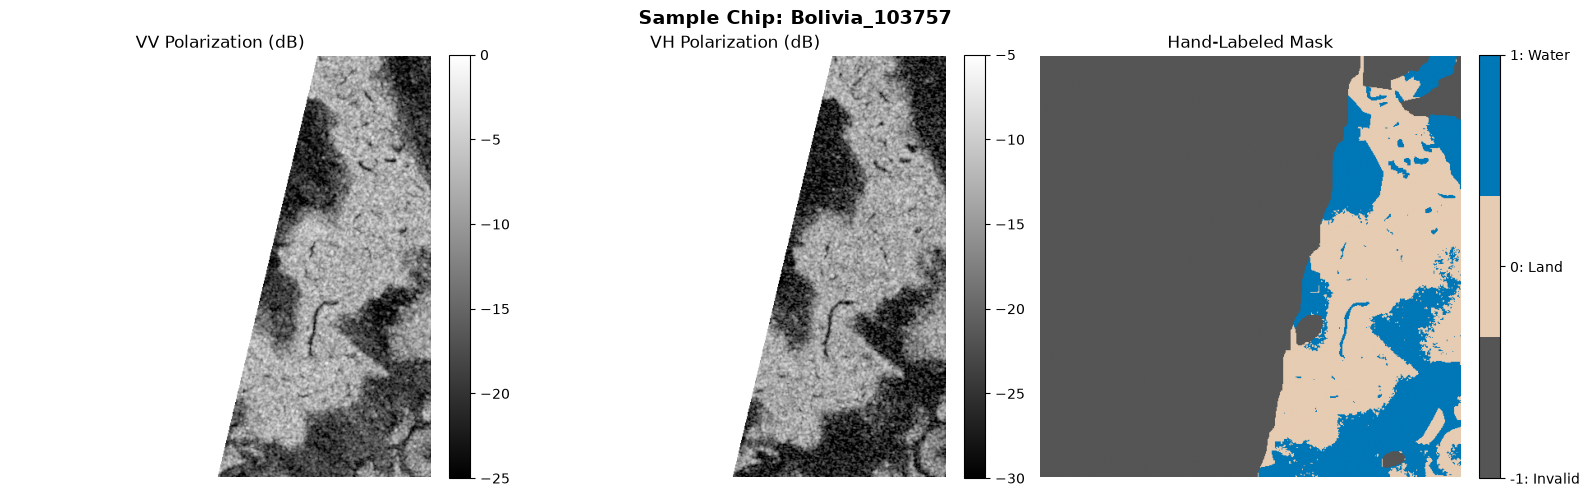

In [2]:
import os
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

DATA_ROOT = r"C:\Users\hosam\OneDrive\Documents\PROJECT\sen1floods11\v1.1\data\flood_events\HandLabeled"
s1_dir = os.path.join(DATA_ROOT, "S1Hand")
label_dir = os.path.join(DATA_ROOT, "LabelHand")

# Pick the first image chip (or specify one like "India_..._S1Hand.tif")
sample_s1_file = sorted([f for f in os.listdir(s1_dir) if f.endswith("_S1Hand.tif")])[0]
sample_label_file = sample_s1_file.replace("_S1Hand.tif", "_LabelHand.tif")

s1_path = os.path.join(s1_dir, sample_s1_file)
label_path = os.path.join(label_dir, sample_label_file)

print(f"🔍 Inspecting Chip: {sample_s1_file}\n" + "-"*50)

# 1. Read the SAR Image
with rasterio.open(s1_path) as src:
    sar_img = src.read()  # Shape: (2, 512, 512) -> Channel 0: VV, Channel 1: VH
    vv = sar_img[0]
    vh = sar_img[1]
    print(f"SAR Shape      : {sar_img.shape} (Channels, Height, Width)")
    print(f"SAR Data Type  : {sar_img.dtype}")
    print(f"SAR NaN count  : {np.isnan(sar_img).sum()} pixels")
    print(f"VV Range (dB)  : min={np.nanmin(vv):.2f}, max={np.nanmax(vv):.2f}, mean={np.nanmean(vv):.2f}")
    print(f"VH Range (dB)  : min={np.nanmin(vh):.2f}, max={np.nanmax(vh):.2f}, mean={np.nanmean(vh):.2f}")

# 2. Read the Water Mask
with rasterio.open(label_path) as src:
    mask = src.read(1)    # Shape: (512, 512)
    unique_vals, counts = np.unique(mask, return_counts=True)
    print(f"\nMask Shape     : {mask.shape}")
    print(f"Mask Data Type : {mask.dtype}")
    print("Mask Pixel Breakdown:")
    for val, count in zip(unique_vals, counts):
        label_name = {-1: "Invalid/Missing", 0: "Land (Non-Water)", 1: "Water"}.get(val, "Unknown")
        pct = (count / mask.size) * 100
        print(f"  Value {val:>2} ({label_name:<16}): {count:>7} pixels ({pct:.2f}%)")

# 3. Plot VV, VH, and Ground-Truth Mask Side-by-Side
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle(f"Sample Chip: {sample_s1_file.replace('_S1Hand.tif', '')}", fontsize=14, fontweight='bold')

# Plot VV Band
im0 = axes[0].imshow(vv, cmap='gray', vmin=-25, vmax=0)
axes[0].set_title("VV Polarization (dB)")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

# Plot VH Band
im1 = axes[1].imshow(vh, cmap='gray', vmin=-30, vmax=-5)
axes[1].set_title("VH Polarization (dB)")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

# Plot Mask (-1: Gray, 0: Tan/Land, 1: Blue/Water)
cmap_mask = ListedColormap(['#555555', '#e6ccb2', '#0077b6'])
im2 = axes[2].imshow(mask, cmap=cmap_mask, vmin=-1, vmax=1)
axes[2].set_title("Hand-Labeled Mask")
cbar = plt.colorbar(im2, ax=axes[2], ticks=[-1, 0, 1], fraction=0.046, pad=0.04)
cbar.ax.set_yticklabels(['-1: Invalid', '0: Land', '1: Water'])

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

In [3]:
import os
import rasterio
import numpy as np

DATA_ROOT = r"C:\Users\hosam\OneDrive\Documents\PROJECT\sen1floods11\v1.1\data\flood_events\HandLabeled"
s1_dir = os.path.join(DATA_ROOT, "S1Hand")
label_dir = os.path.join(DATA_ROOT, "LabelHand")

all_s1_files = sorted([f for f in os.listdir(s1_dir) if f.endswith("_S1Hand.tif")])

# ---------------------------------------------------------
# 1. GEOGRAPHIC SPLIT (Part 3, Step 1: Group by Location/Event)
# ---------------------------------------------------------
# Unseen Test Regions: Bolivia (15), Mekong (30), Spain (30) -> 75 chips (~16.8%)
# Validation Regions : Somalia (26), Nigeria (18), Pakistan (28) -> 72 chips (~16.1%)
# Training Regions   : USA (69), India (68), Paraguay (67), Ghana (53), Sri-Lanka (42) -> 299 chips (~67.0%)

TEST_REGIONS  = {"Bolivia", "Mekong", "Spain"}
VAL_REGIONS   = {"Somalia", "Nigeria", "Pakistan"}
TRAIN_REGIONS = {"USA", "India", "Paraguay", "Ghana", "Sri-Lanka"}

train_files, val_files, test_files = [], [], []

for f in all_s1_files:
    country = f.split("_")[0]
    if country in TRAIN_REGIONS:
        train_files.append(f)
    elif country in VAL_REGIONS:
        val_files.append(f)
    elif country in TEST_REGIONS:
        test_files.append(f)

print(f"📊 Geographic Split Summary:")
print(f"  Train chips : {len(train_files)} (Regions: {sorted(TRAIN_REGIONS)})")
print(f"  Val chips   : {len(val_files)} (Regions: {sorted(VAL_REGIONS)})")
print(f"  Test chips  : {len(test_files)} (Unseen Regions: {sorted(TEST_REGIONS)})\n")

# ---------------------------------------------------------
# 2. COMPUTE MEAN & STD ON TRAINING SET ONLY (No Leakage!)
# ---------------------------------------------------------
vv_sum, vh_sum = 0.0, 0.0
vv_sq_sum, vh_sq_sum = 0.0, 0.0
valid_pixel_count = 0

for s1_file in train_files:
    s1_path = os.path.join(s1_dir, s1_file)
    label_path = os.path.join(label_dir, s1_file.replace("_S1Hand.tif", "_LabelHand.tif"))
    
    with rasterio.open(s1_path) as src_s1, rasterio.open(label_path) as src_lbl:
        sar = src_s1.read().astype(np.float64) # (2, 512, 512)
        mask = src_lbl.read(1)                 # (512, 512)
        
    vv, vh = sar[0], sar[1]
    
    # Valid pixels: mask is NOT -1 AND neither VV nor VH is NaN/Inf
    valid = (mask != -1) & (~np.isnan(vv)) & (~np.isnan(vh)) & (~np.isinf(vv)) & (~np.isinf(vh))
    
    valid_vv = vv[valid]
    valid_vh = vh[valid]
    
    vv_sum += valid_vv.sum()
    vh_sum += valid_vh.sum()
    vv_sq_sum += np.square(valid_vv).sum()
    vh_sq_sum += np.square(valid_vh).sum()
    valid_pixel_count += valid_vv.size

# Calculate exact Mean and Standard Deviation
vv_mean = vv_sum / valid_pixel_count
vh_mean = vh_sum / valid_pixel_count

vv_std = np.sqrt((vv_sq_sum / valid_pixel_count) - np.square(vv_mean))
vh_std = np.sqrt((vh_sq_sum / valid_pixel_count) - np.square(vh_mean))

print("✅ Training Set Normalization Constants (Valid Pixels Only):")
print(f"  Valid training pixels analyzed: {valid_pixel_count:,}")
print(f"  VV_MEAN = {vv_mean:.4f}, VV_STD = {vv_std:.4f}")
print(f"  VH_MEAN = {vh_mean:.4f}, VH_STD = {vh_std:.4f}")

📊 Geographic Split Summary:
  Train chips : 299 (Regions: ['Ghana', 'India', 'Paraguay', 'Sri-Lanka', 'USA'])
  Val chips   : 72 (Regions: ['Nigeria', 'Pakistan', 'Somalia'])
  Test chips  : 75 (Unseen Regions: ['Bolivia', 'Mekong', 'Spain'])

✅ Training Set Normalization Constants (Valid Pixels Only):
  Valid training pixels analyzed: 68,369,177
  VV_MEAN = -10.1397, VV_STD = 3.8141
  VH_MEAN = -16.9252, VH_STD = 4.3560


In [4]:
def load_and_preprocess_chip(s1_path, label_path, stats, mode="zscore"):
    """
    Loads a Sentinel-1 chip and mask, cleans NaNs/-1s, and normalizes.
    mode: "zscore" (Experiment 1A) or "minmax_clip" (Experiment 1B: clip -30 to 0 dB)
    """
    with rasterio.open(s1_path) as src_s1, rasterio.open(label_path) as src_lbl:
        sar = src_s1.read().astype(np.float32) # (2, 512, 512)
        mask = src_lbl.read(1).astype(np.int16) # (512, 512)

    vv, vh = sar[0], sar[1]

    # 1. Build combined validity mask (1.0 where valid, 0.0 where mask==-1 or SAR is NaN)
    valid = (mask != -1) & (~np.isnan(vv)) & (~np.isnan(vh)) & (~np.isinf(vv)) & (~np.isinf(vh))
    valid_mask = valid.astype(np.float32)[..., np.newaxis] # Shape: (512, 512, 1)

    # 2. Normalize valid pixels (Experiment 1 ready!)
    if mode == "zscore":
        vv_norm = (vv - stats["vv_mean"]) / stats["vv_std"]
        vh_norm = (vh - stats["vh_mean"]) / stats["vh_std"]
    elif mode == "minmax_clip":
        # Clip between -30 dB and 0 dB, then scale to [0, 1]
        vv_norm = (np.clip(vv, -30.0, 0.0) - (-30.0)) / 30.0
        vh_norm = (np.clip(vh, -30.0, 0.0) - (-30.0)) / 30.0
    else:
        raise ValueError(f"Unknown normalization mode: {mode}")

    # 3. Replace NaNs / invalid pixels with 0.0 so Conv2D layers don't break
    vv_norm = np.where(valid, vv_norm, 0.0)
    vh_norm = np.where(valid, vh_norm, 0.0)

    # 4. Stack into Channels-Last (512, 512, 2) for TensorFlow/Keras
    X = np.stack([vv_norm, vh_norm], axis=-1).astype(np.float32)

    # 5. Clean target mask: replace -1 with 0 (valid_mask will zero out its loss anyway)
    y = np.where(valid, mask, 0).astype(np.float32)[..., np.newaxis] # Shape: (512, 512, 1)

    return X, y, valid_mask

✅ Preprocessed X shape : (512, 512, 2) | NaN count: 0
✅ Preprocessed y shape : (512, 512, 1) | Unique values in y: [0. 1.]
✅ Valid mask shape     : (512, 512, 1) | Unique values: [0. 1.]
✅ Normalized VV mean (on valid pixels): -0.66


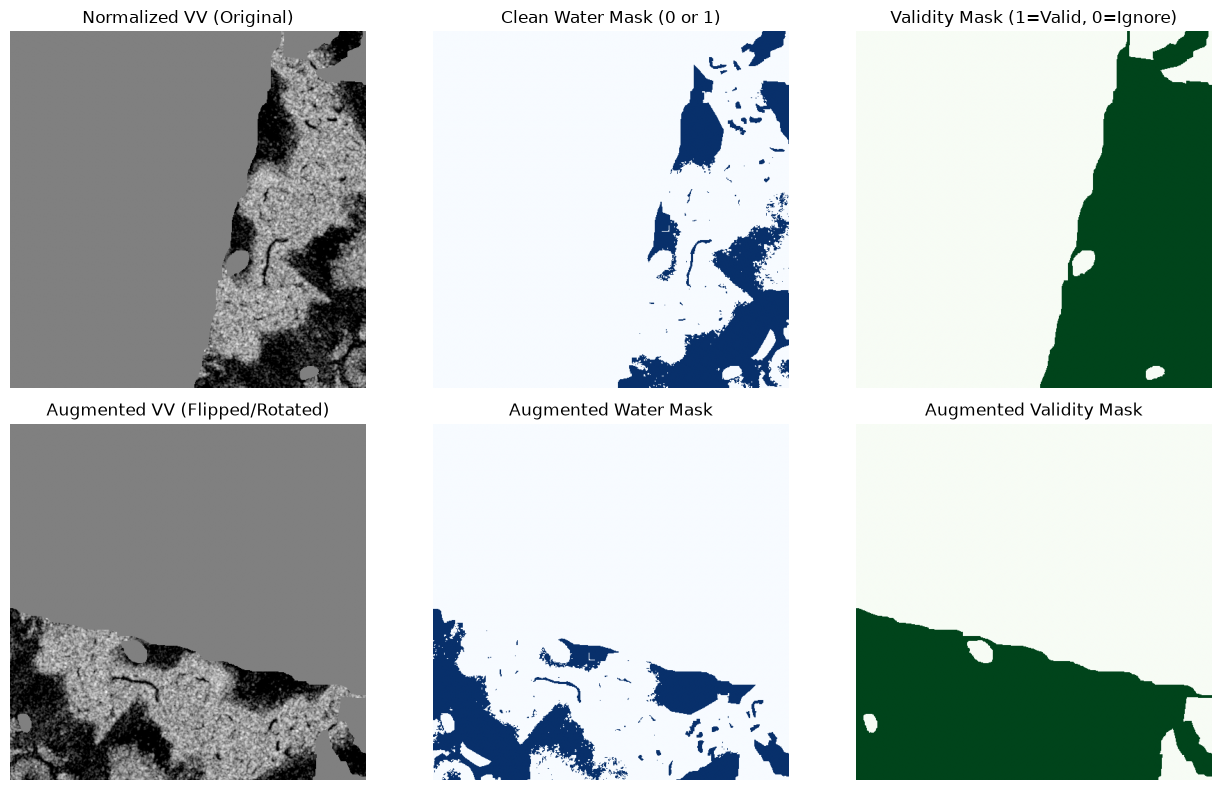

In [5]:
import os
import rasterio
import numpy as np
import matplotlib.pyplot as plt

# Your exact Training Set constants from Step 3A
TRAIN_STATS = {
    "vv_mean": -10.1397,
    "vv_std": 3.8141,
    "vh_mean": -16.9252,
    "vh_std": 4.3560
}

def load_and_preprocess_chip(s1_path, label_path, stats=TRAIN_STATS, mode="zscore"):
    with rasterio.open(s1_path) as src_s1, rasterio.open(label_path) as src_lbl:
        sar = src_s1.read().astype(np.float32)  # (2, 512, 512)
        mask = src_lbl.read(1).astype(np.int16) # (512, 512)

    vv, vh = sar[0], sar[1]

    # 1. Validity mask: 1.0 where pixel is valid, 0.0 where mask is -1 or radar is NaN
    valid = (mask != -1) & (~np.isnan(vv)) & (~np.isnan(vh)) & (~np.isinf(vv)) & (~np.isinf(vh))
    valid_mask = valid.astype(np.float32)[..., np.newaxis] # (512, 512, 1)

    # 2. Normalize (Z-score or Min-Max Clipping for Experiment 1)
    if mode == "zscore":
        vv_norm = (vv - stats["vv_mean"]) / stats["vv_std"]
        vh_norm = (vh - stats["vh_mean"]) / stats["vh_std"]
    elif mode == "minmax_clip":
        vv_norm = (np.clip(vv, -30.0, 0.0) + 30.0) / 30.0
        vh_norm = (np.clip(vh, -30.0, 0.0) + 30.0) / 30.0

    # 3. Replace invalid/NaN pixels with 0.0 so neural network math never hits NaN
    vv_norm = np.where(valid, vv_norm, 0.0)
    vh_norm = np.where(valid, vh_norm, 0.0)

    # 4. Stack as (512, 512, 2) for Keras
    X = np.stack([vv_norm, vh_norm], axis=-1).astype(np.float32)

    # 5. Clean mask: (512, 512, 1) with only 0.0 (Land) and 1.0 (Water)
    y = np.where(valid, mask, 0).astype(np.float32)[..., np.newaxis]

    return X, y, valid_mask


def augment_chip(X, y, valid_mask):
    """
    Part 2, Step 4: Flips and rotates X, y, and valid_mask identically.
    Because 90-degree rotations and flips snap to exact pixel grids,
    0 and 1 mask values never turn into decimals!
    """
    # Random Horizontal Flip (50% chance)
    if np.random.rand() > 0.5:
        X = np.fliplr(X)
        y = np.fliplr(y)
        valid_mask = np.fliplr(valid_mask)

    # Random Vertical Flip (50% chance)
    if np.random.rand() > 0.5:
        X = np.flipud(X)
        y = np.flipud(y)
        valid_mask = np.flipud(valid_mask)

    # Random 90-degree rotation (0, 90, 180, or 270 degrees)
    k = np.random.randint(0, 4)
    if k > 0:
        X = np.rot90(X, k, axes=(0, 1))
        y = np.rot90(y, k, axes=(0, 1))
        valid_mask = np.rot90(valid_mask, k, axes=(0, 1))

    return X, y, valid_mask


# --- TEST & VERIFY ON ONE CHIP ---
s1_sample = r"C:\Users\hosam\OneDrive\Documents\PROJECT\sen1floods11\v1.1\data\flood_events\HandLabeled/S1Hand/Bolivia_103757_S1Hand.tif"
lbl_sample = r"C:\Users\hosam\OneDrive\Documents\PROJECT\sen1floods11\v1.1\data\flood_events\HandLabeled/LabelHand/Bolivia_103757_LabelHand.tif"

X, y, valid_mask = load_and_preprocess_chip(s1_sample, lbl_sample)
X_aug, y_aug, valid_aug = augment_chip(X, y, valid_mask)

print(f"✅ Preprocessed X shape : {X.shape} | NaN count: {np.isnan(X).sum()}")
print(f"✅ Preprocessed y shape : {y.shape} | Unique values in y: {np.unique(y)}")
print(f"✅ Valid mask shape     : {valid_mask.shape} | Unique values: {np.unique(valid_mask)}")
print(f"✅ Normalized VV mean (on valid pixels): {X[..., 0][valid_mask[..., 0] == 1].mean():.2f}")

# Plot Original vs Augmented to verify alignment
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes[0, 0].imshow(X[..., 0], cmap='gray', vmin=-2.5, vmax=2.5)
axes[0, 0].set_title("Normalized VV (Original)")
axes[0, 1].imshow(y[..., 0], cmap='Blues')
axes[0, 1].set_title("Clean Water Mask (0 or 1)")
axes[0, 2].imshow(valid_mask[..., 0], cmap='Greens')
axes[0, 2].set_title("Validity Mask (1=Valid, 0=Ignore)")

axes[1, 0].imshow(X_aug[..., 0], cmap='gray', vmin=-2.5, vmax=2.5)
axes[1, 0].set_title("Augmented VV (Flipped/Rotated)")
axes[1, 1].imshow(y_aug[..., 0], cmap='Blues')
axes[1, 1].set_title("Augmented Water Mask")
axes[1, 2].imshow(valid_aug[..., 0], cmap='Greens')
axes[1, 2].set_title("Augmented Validity Mask")

for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [7]:
import tensorflow as tf
from tensorflow.keras import layers, models

# ---------------------------------------------------------
# 1. KERAS DATA GENERATOR (Loads batches & packs [y, valid_mask])
# ---------------------------------------------------------
class Sen1FloodsGenerator(tf.keras.utils.Sequence):
    def __init__(self, file_list, s1_dir, label_dir, batch_size=2, 
                 norm_mode="zscore", augment=False, shuffle=True):
        self.file_list = file_list
        self.s1_dir = s1_dir
        self.label_dir = label_dir
        self.batch_size = batch_size
        self.norm_mode = norm_mode
        self.augment = augment
        self.shuffle = shuffle
        self.indexes = np.arange(len(self.file_list))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.file_list) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __getitem__(self, index):
        batch_idxs = self.indexes[index * self.batch_size : (index + 1) * self.batch_size]
        batch_files = [self.file_list[k] for k in batch_idxs]

        X_batch, y_comb_batch = [], []

        for s1_file in batch_files:
            s1_path = os.path.join(self.s1_dir, s1_file)
            lbl_path = os.path.join(self.label_dir, s1_file.replace("_S1Hand.tif", "_LabelHand.tif"))

            X, y, valid_mask = load_and_preprocess_chip(s1_path, lbl_path, mode=self.norm_mode)

            if self.augment:
                X, y, valid_mask = augment_chip(X, y, valid_mask)

            # Pack y (channel 0) and valid_mask (channel 1) together -> (512, 512, 2)
            y_combined = np.concatenate([y, valid_mask], axis=-1)

            X_batch.append(X)
            y_comb_batch.append(y_combined)

        return np.array(X_batch, dtype=np.float32), np.array(y_comb_batch, dtype=np.float32)


# ---------------------------------------------------------
# 2. MASKED LOSS & METRICS (Ignores -1 / NaN pixels completely!)
# ---------------------------------------------------------
def masked_bce_dice_loss(y_true_comb, y_pred):
    y_true = y_true_comb[..., 0:1] # Actual water mask (0 or 1)
    valid  = y_true_comb[..., 1:2] # Validity mask (1=valid, 0=ignore)

    # Clip predictions slightly to avoid log(0)
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)

    # 1. Masked Binary Cross-Entropy
    bce = - (y_true * tf.math.log(y_pred) + (1.0 - y_true) * tf.math.log(1.0 - y_pred))
    bce_masked = tf.reduce_sum(bce * valid) / (tf.reduce_sum(valid) + 1e-7)

    # 2. Masked Soft Dice Loss
    intersection = tf.reduce_sum(y_true * y_pred * valid)
    union = tf.reduce_sum((y_true + y_pred) * valid)
    dice_loss = 1.0 - (2.0 * intersection + 1e-5) / (union + 1e-5)

    return bce_masked + dice_loss

def masked_iou(y_true_comb, y_pred):
    y_true = y_true_comb[..., 0:1]
    valid  = y_true_comb[..., 1:2]
    y_pred_bin = tf.cast(y_pred > 0.5, tf.float32)

    tp = tf.reduce_sum(y_true * y_pred_bin * valid)
    fp = tf.reduce_sum((1.0 - y_true) * y_pred_bin * valid)
    fn = tf.reduce_sum(y_true * (1.0 - y_pred_bin) * valid)

    return (tp + 1e-5) / (tp + fp + fn + 1e-5)

def masked_dice(y_true_comb, y_pred):
    y_true = y_true_comb[..., 0:1]
    valid  = y_true_comb[..., 1:2]
    y_pred_bin = tf.cast(y_pred > 0.5, tf.float32)

    tp = tf.reduce_sum(y_true * y_pred_bin * valid)
    fp = tf.reduce_sum((1.0 - y_true) * y_pred_bin * valid)
    fn = tf.reduce_sum(y_true * (1.0 - y_pred_bin) * valid)

    return (2.0 * tp + 1e-5) / (2.0 * tp + fp + fn + 1e-5)


# ---------------------------------------------------------
# 3. STANDARD U-NET ARCHITECTURE (512, 512, 2) -> (512, 512, 1)
# ---------------------------------------------------------
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    return x

def build_unet(input_shape=(512, 512, 2), base_filters=32):
    inputs = layers.Input(shape=input_shape)

    # Encoder (Downsampling path)
    c1 = conv_block(inputs, base_filters)        # 512x512
    p1 = layers.MaxPooling2D((2, 2))(c1)         # 256x256

    c2 = conv_block(p1, base_filters * 2)        # 256x256
    p2 = layers.MaxPooling2D((2, 2))(c2)         # 128x128

    c3 = conv_block(p2, base_filters * 4)        # 128x128
    p3 = layers.MaxPooling2D((2, 2))(c3)         # 64x64

    c4 = conv_block(p3, base_filters * 8)        # 64x64
    p4 = layers.MaxPooling2D((2, 2))(c4)         # 32x32

    # Bottleneck
    bn = conv_block(p4, base_filters * 16)       # 32x32

    # Decoder (Upsampling path + Skip Connections)
    u4 = layers.UpSampling2D((2, 2))(bn)         # 64x64
    u4 = layers.Concatenate()([u4, c4])
    d4 = conv_block(u4, base_filters * 8)

    u3 = layers.UpSampling2D((2, 2))(d4)         # 128x128
    u3 = layers.Concatenate()([u3, c3])
    d3 = conv_block(u3, base_filters * 4)

    u2 = layers.UpSampling2D((2, 2))(d3)         # 256x256
    u2 = layers.Concatenate()([u2, c2])
    d2 = conv_block(u2, base_filters * 2)

    u1 = layers.UpSampling2D((2, 2))(d2)         # 512x512
    u1 = layers.Concatenate()([u1, c1])
    d1 = conv_block(u1, base_filters)

    # Output layer: 1 channel water probability (0.0 to 1.0)
    outputs = layers.Conv2D(1, (1, 1), activation="sigmoid")(d1)

    model = models.Model(inputs, outputs, name="FloodShift_UNet")
    return model

# --- INSTANTIATE & VERIFY PIPELINE ---
train_gen = Sen1FloodsGenerator(train_files, s1_dir, label_dir, batch_size=4, norm_mode="zscore", augment=True)
val_gen   = Sen1FloodsGenerator(val_files, s1_dir, label_dir, batch_size=4, norm_mode="zscore", augment=False, shuffle=False)
test_gen  = Sen1FloodsGenerator(test_files, s1_dir, label_dir, batch_size=4, norm_mode="zscore", augment=False, shuffle=False)

X_batch, y_comb_batch = train_gen[0]
print(f"✅ Generator Batch X shape      : {X_batch.shape}")
print(f"✅ Generator Batch y_comb shape : {y_comb_batch.shape} (Channel 0=Mask, Channel 1=Valid)")

model = build_unet(input_shape=(512, 512, 2), base_filters=32)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=masked_bce_dice_loss,
    metrics=[masked_iou, masked_dice]
)
print(f"✅ U-Net Built Successfully! Total Parameters: {model.count_params():,}")

✅ Generator Batch X shape      : (4, 512, 512, 2)
✅ Generator Batch y_comb shape : (4, 512, 512, 2) (Channel 0=Mask, Channel 1=Valid)
✅ U-Net Built Successfully! Total Parameters: 7,855,201


In [13]:
import os
import tensorflow as tf

# 1. Create a directory to save your trained weights and experimental results
os.makedirs("experiments/weights", exist_ok=True)
os.makedirs("figures", exist_ok=True)

# 2. Setup lightweight generators optimized for CPU (batch_size = 2)
train_gen_cpu = Sen1FloodsGenerator(
    file_list=train_files, 
    s1_dir=s1_dir, 
    label_dir=label_dir, 
    batch_size=2,          # Smaller batch size for CPU RAM
    norm_mode="zscore", 
    augment=True
)

val_gen_cpu = Sen1FloodsGenerator(
    file_list=val_files, 
    s1_dir=s1_dir, 
    label_dir=label_dir, 
    batch_size=2, 
    norm_mode="zscore", 
    augment=False, 
    shuffle=False
)

# 3. Define Callbacks (Save best model based on Validation IoU)
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="experiments/weights/unet_baseline_best.keras",
        monitor="val_masked_iou",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_masked_iou",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    )
]

print("🚀 Starting CPU Baseline Training (Experiment 1: Z-Score Normalization)...")
print(f"   Training batches per epoch: {len(train_gen_cpu)}")
print(f"   Validation batches: {len(val_gen_cpu)}")

# 4. Fit the model (Start with 5-10 epochs for a local CPU run)
history = model.fit(
    train_gen_cpu,
    validation_data=val_gen_cpu,
    epochs=10,
    callbacks=callbacks,
    verbose=1
)

🚀 Starting CPU Baseline Training (Experiment 1: Z-Score Normalization)...
   Training batches per epoch: 150
   Validation batches: 36
Epoch 1/10


150/150 [==============================] - ETA: 0s - loss: 1.0406 - masked_iou: 0.2854 - masked_dice: 0.3950 
Epoch 1: val_masked_iou improved from -inf to 0.19699, saving model to experiments/weights\unet_baseline_best.keras
150/150 [==============================] - 1812s 12s/step - loss: 1.0406 - masked_iou: 0.2854 - masked_dice: 0.3950 - val_loss: 2.3494 - val_masked_iou: 0.1970 - val_masked_dice: 0.2805
Epoch 2/10
150/150 [==============================] - ETA: 0s - loss: 0.8540 - masked_iou: 0.3454 - masked_dice: 0.4648 
Epoch 2: val_masked_iou improved from 0.19699 to 0.26846, saving model to experiments/weights\unet_baseline_best.keras
150/150 [==============================] - 1626s 11s/step - loss: 0.8540 - masked_iou: 0.3454 - masked_dice: 0.4648 - val_loss: 1.1556 - val_masked_iou: 0.2685 - val_masked_dice: 0.3640
Epoch 3/10
150

✅ Loaded best saved model from: experiments/weights/unet_baseline_best.keras

🌍 UNSEEN TEST SET RESULTS (Cross-Regional Generalization):
-----------------------------------------------------------------
Unseen Region   | IoU Score    | Dice Score   | Precision  | Recall    
-----------------------------------------------------------------
Bolivia         | 0.7273       | 0.8421       | 0.8183     | 0.8673    
Mekong          | 0.8642       | 0.9272       | 0.9445     | 0.9105    
Spain           | 0.6269       | 0.7706       | 0.6641     | 0.9179    
-----------------------------------------------------------------
OVERALL TEST    | 0.7530       | 0.8591      
-----------------------------------------------------------------


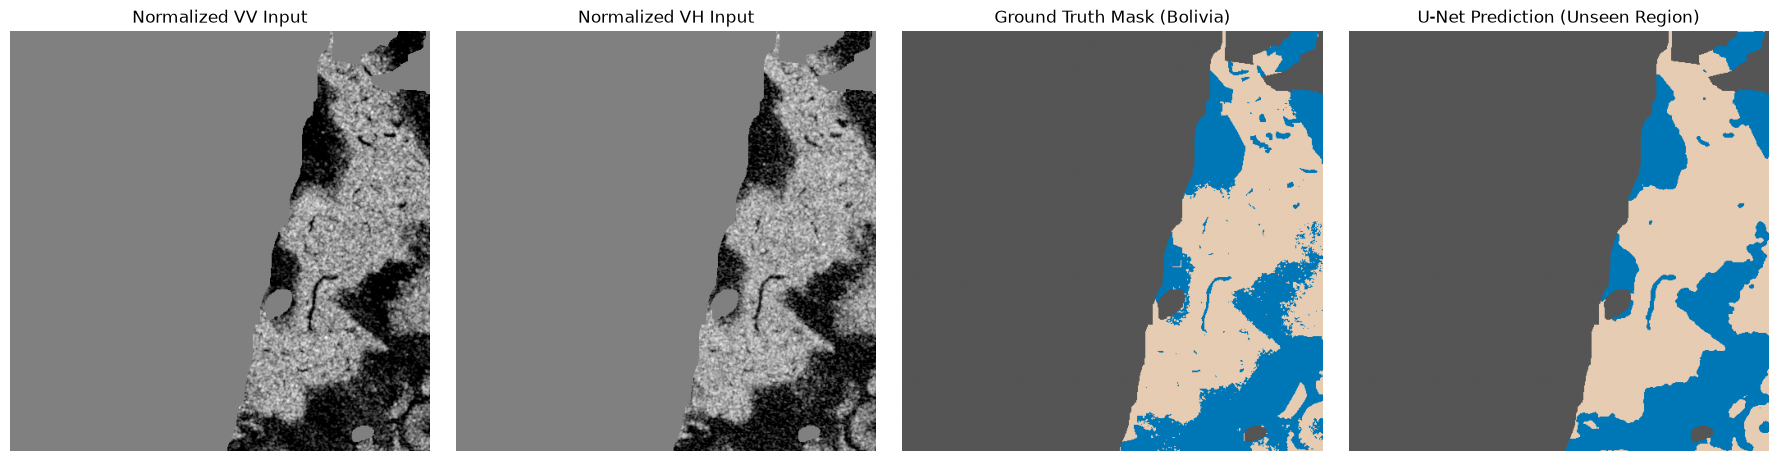

In [14]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# 1. Load the best saved weights from your training run
best_model_path = "experiments/weights/unet_baseline_best.keras"
model.load_weights(best_model_path)
print(f"✅ Loaded best saved model from: {best_model_path}\n")

# 2. Evaluate on Unseen Test Regions (Per-Country & Overall Pixel-Level IoU/Dice)
# Computing true dataset-level TP, FP, FN across all valid pixels in each country
region_stats = {region: {"tp": 0.0, "fp": 0.0, "fn": 0.0} for region in TEST_REGIONS}

for s1_file in test_files:
    country = s1_file.split("_")[0]
    s1_path = os.path.join(s1_dir, s1_file)
    lbl_path = os.path.join(label_dir, s1_file.replace("_S1Hand.tif", "_LabelHand.tif"))

    X, y, valid_mask = load_and_preprocess_chip(s1_path, lbl_path, mode="zscore")
    
    # Predict water probability map (1, 512, 512, 1) -> (512, 512, 1)
    y_pred_prob = model.predict(X[np.newaxis, ...], verbose=0)[0]
    y_pred_bin = (y_pred_prob > 0.5).astype(np.float32)

    # Count TP, FP, FN on valid pixels only
    tp = np.sum(y * y_pred_bin * valid_mask)
    fp = np.sum((1.0 - y) * y_pred_bin * valid_mask)
    fn = np.sum(y * (1.0 - y_pred_bin) * valid_mask)

    region_stats[country]["tp"] += tp
    region_stats[country]["fp"] += fp
    region_stats[country]["fn"] += fn

print("🌍 UNSEEN TEST SET RESULTS (Cross-Regional Generalization):")
print("-" * 65)
print(f"{'Unseen Region':<15} | {'IoU Score':<12} | {'Dice Score':<12} | {'Precision':<10} | {'Recall':<10}")
print("-" * 65)

total_tp, total_fp, total_fn = 0.0, 0.0, 0.0
for country, st in sorted(region_stats.items()):
    tp, fp, fn = st["tp"], st["fp"], st["fn"]
    total_tp += tp; total_fp += fp; total_fn += fn
    
    iou  = tp / (tp + fp + fn + 1e-7)
    dice = (2.0 * tp) / (2.0 * tp + fp + fn + 1e-7)
    prec = tp / (tp + fp + 1e-7)
    rec  = tp / (tp + fn + 1e-7)
    print(f"{country:<15} | {iou:<12.4f} | {dice:<12.4f} | {prec:<10.4f} | {rec:<10.4f}")

print("-" * 65)
overall_iou  = total_tp / (total_tp + total_fp + total_fn + 1e-7)
overall_dice = (2.0 * total_tp) / (2.0 * total_tp + total_fp + total_fn + 1e-7)
print(f"{'OVERALL TEST':<15} | {overall_iou:<12.4f} | {overall_dice:<12.4f}")
print("-" * 65)

# 3. Plot Visual Prediction on a Sample Unseen Test Chip (Bolivia)
sample_test = "Bolivia_103757_S1Hand.tif"
X_test, y_test, valid_test = load_and_preprocess_chip(
    os.path.join(s1_dir, sample_test),
    os.path.join(label_dir, sample_test.replace("_S1Hand.tif", "_LabelHand.tif")),
    mode="zscore"
)
pred_prob = model.predict(X_test[np.newaxis, ...], verbose=0)[0, ..., 0]
pred_mask = (pred_prob > 0.5).astype(np.int16)

# Restore -1 for invalid pixels so the plot shows gray borders cleanly
gt_plot   = np.where(valid_test[..., 0] == 1, y_test[..., 0], -1)
pred_plot = np.where(valid_test[..., 0] == 1, pred_mask, -1)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
cmap_mask = ListedColormap(['#555555', '#e6ccb2', '#0077b6'])

axes[0].imshow(X_test[..., 0], cmap='gray', vmin=-2.5, vmax=2.5)
axes[0].set_title("Normalized VV Input")

axes[1].imshow(X_test[..., 1], cmap='gray', vmin=-2.5, vmax=2.5)
axes[1].set_title("Normalized VH Input")

axes[2].imshow(gt_plot, cmap=cmap_mask, vmin=-1, vmax=1)
axes[2].set_title("Ground Truth Mask (Bolivia)")

axes[3].imshow(pred_plot, cmap=cmap_mask, vmin=-1, vmax=1)
axes[3].set_title("U-Net Prediction (Unseen Region)")

for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/baseline_prediction_bolivia.png", dpi=150)
plt.show()

In [10]:
import os
import gc
import time
import json
import rasterio
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from scipy.ndimage import uniform_filter

# 1. Verify paths and splits
DATA_ROOT = r"C:\Users\hosam\OneDrive\Documents\PROJECT\sen1floods11\v1.1\data\flood_events\HandLabeled"
s1_dir = os.path.join(DATA_ROOT, "S1Hand")
label_dir = os.path.join(DATA_ROOT, "LabelHand")
all_s1_files = sorted([f for f in os.listdir(s1_dir) if f.endswith("_S1Hand.tif")])

TEST_REGIONS  = {"Bolivia", "Mekong", "Spain"}
VAL_REGIONS   = {"Somalia", "Nigeria", "Pakistan"}
TRAIN_REGIONS = {"USA", "India", "Paraguay", "Ghana", "Sri-Lanka"}

np.random.seed(42)
familiar_all = sorted([f for f in all_s1_files if f.split("_")[0] in TRAIN_REGIONS])
val_files    = sorted([f for f in all_s1_files if f.split("_")[0] in VAL_REGIONS])
ood_test_files = sorted([f for f in all_s1_files if f.split("_")[0] in TEST_REGIONS])

id_test_files = familiar_all[::7]
train_files_clean = [f for f in familiar_all if f not in set(id_test_files)]

TRAIN_STATS = {
    "vv_mean": -10.1397, "vv_std": 3.8141, "vv_p01": -22.50, "vv_p99": -1.50,
    "vh_mean": -16.9252, "vh_std": 4.3560, "vh_p01": -29.50, "vh_p99": -7.50
}

# 2. Define Lee Filter, Preprocessing & Augmentation
def lee_filter(band, window_size=5):
    img = band.astype(np.float64)
    img_mean = uniform_filter(img, size=window_size)
    img_sqr_mean = uniform_filter(img**2, size=window_size)
    img_variance = np.maximum(img_sqr_mean - img_mean**2, 0.0)
    overall_variance = np.var(img)
    weights = img_variance / (img_variance + overall_variance + 1e-8)
    filtered = img_mean + weights * (img - img_mean)
    return filtered.astype(np.float32)

def load_and_preprocess_chip(s1_path, label_path, stats=TRAIN_STATS, mode="zscore", use_lee_filter=False):
    with rasterio.open(s1_path) as src_s1, rasterio.open(label_path) as src_lbl:
        sar = src_s1.read().astype(np.float32)
        mask = src_lbl.read(1).astype(np.int16)

    vv, vh = sar[0], sar[1]
    valid = (mask != -1) & (~np.isnan(vv)) & (~np.isnan(vh)) & (~np.isinf(vv)) & (~np.isinf(vh))
    valid_mask = valid.astype(np.float32)[..., np.newaxis]

    vv_clean = np.where(valid, vv, stats["vv_mean"])
    vh_clean = np.where(valid, vh, stats["vh_mean"])

    if use_lee_filter:
        vv_clean = lee_filter(vv_clean, window_size=5)
        vh_clean = lee_filter(vh_clean, window_size=5)

    if mode == "raw_db":
        vv_norm, vh_norm = vv_clean, vh_clean
    elif mode == "minmax_clip":
        vv_norm = (np.clip(vv_clean, -30.0, 0.0) + 30.0) / 30.0
        vh_norm = (np.clip(vh_clean, -30.0, 0.0) + 30.0) / 30.0
    elif mode == "zscore":
        vv_norm = (vv_clean - stats["vv_mean"]) / stats["vv_std"]
        vh_norm = (vh_clean - stats["vh_mean"]) / stats["vh_std"]
    elif mode == "percentile":
        vv_clip = np.clip(vv_clean, stats["vv_p01"], stats["vv_p99"])
        vh_clip = np.clip(vh_clean, stats["vh_p01"], stats["vh_p99"])
        vv_norm = (vv_clip - stats["vv_mean"]) / stats["vv_std"]
        vh_norm = (vh_clip - stats["vh_mean"]) / stats["vh_std"]
    else:
        raise ValueError(f"Unknown mode: {mode}")

    vv_norm = np.where(valid, vv_norm, 0.0)
    vh_norm = np.where(valid, vh_norm, 0.0)

    X = np.stack([vv_norm, vh_norm], axis=-1).astype(np.float32)
    y = np.where(valid, mask, 0).astype(np.float32)[..., np.newaxis]
    return X, y, valid_mask

def augment_chip(X, y, valid_mask, aug_mode="none"):
    if aug_mode == "none":
        return X, y, valid_mask
    if aug_mode in ["geometric", "combined"]:
        if np.random.rand() > 0.5:
            X, y, valid_mask = np.fliplr(X), np.fliplr(y), np.fliplr(valid_mask)
        if np.random.rand() > 0.5:
            X, y, valid_mask = np.flipud(X), np.flipud(y), np.flipud(valid_mask)
        k = np.random.randint(0, 4)
        if k > 0:
            X = np.rot90(X, k, axes=(0, 1))
            y = np.rot90(y, k, axes=(0, 1))
            valid_mask = np.rot90(valid_mask, k, axes=(0, 1))
    if aug_mode in ["intensity", "combined"]:
        if np.random.rand() > 0.5:
            shift = np.random.uniform(-0.15, 0.15)
            noise = np.random.normal(0.0, 0.08, size=X.shape).astype(np.float32)
            X = np.where(valid_mask == 1.0, X + shift + noise, 0.0)
    return X, y, valid_mask

# 3. In-Memory Generator, Loss, Metrics & U-Net
class InMemoryResearchGenerator(tf.keras.utils.Sequence):
    def __init__(self, file_list, s1_dir, label_dir, batch_size=2, 
                 norm_mode="zscore", use_lee_filter=False, aug_mode="none", shuffle=True):
        self.batch_size = batch_size
        self.aug_mode = aug_mode
        self.shuffle = shuffle
        print(f"⏳ Pre-loading {len(file_list)} chips into RAM (mode={norm_mode}, lee={use_lee_filter})...")
        t0 = time.time()
        self.X_data, self.y_data, self.valid_data = [], [], []
        for f in file_list:
            s1_path = os.path.join(s1_dir, f)
            lbl_path = os.path.join(label_dir, f.replace("_S1Hand.tif", "_LabelHand.tif"))
            X, y, valid_mask = load_and_preprocess_chip(
                s1_path, lbl_path, mode=norm_mode, use_lee_filter=use_lee_filter
            )
            self.X_data.append(X); self.y_data.append(y); self.valid_data.append(valid_mask)
        print(f"✅ Pre-loaded {len(file_list)} chips in {time.time() - t0:.1f}s!")
        self.indexes = np.arange(len(file_list))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.X_data) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __getitem__(self, index):
        batch_idxs = self.indexes[index * self.batch_size : (index + 1) * self.batch_size]
        X_batch, y_comb_batch = [], []
        for k in batch_idxs:
            X, y, valid_mask = self.X_data[k].copy(), self.y_data[k].copy(), self.valid_data[k].copy()
            if self.aug_mode != "none":
                X, y, valid_mask = augment_chip(X, y, valid_mask, aug_mode=self.aug_mode)
            y_combined = np.concatenate([y, valid_mask], axis=-1)
            X_batch.append(X); y_comb_batch.append(y_combined)
        return np.array(X_batch, dtype=np.float32), np.array(y_comb_batch, dtype=np.float32)

def masked_bce_dice_loss(y_true_comb, y_pred):
    y_true, valid = y_true_comb[..., 0:1], y_true_comb[..., 1:2]
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
    bce = - (y_true * tf.math.log(y_pred) + (1.0 - y_true) * tf.math.log(1.0 - y_pred))
    bce_masked = tf.reduce_sum(bce * valid) / (tf.reduce_sum(valid) + 1e-7)
    intersection = tf.reduce_sum(y_true * y_pred * valid)
    union = tf.reduce_sum((y_true + y_pred) * valid)
    dice_loss = 1.0 - (2.0 * intersection + 1e-5) / (union + 1e-5)
    return bce_masked + dice_loss

def masked_iou(y_true_comb, y_pred):
    y_true, valid = y_true_comb[..., 0:1], y_true_comb[..., 1:2]
    y_pred_bin = tf.cast(y_pred > 0.5, tf.float32)
    tp = tf.reduce_sum(y_true * y_pred_bin * valid)
    fp = tf.reduce_sum((1.0 - y_true) * y_pred_bin * valid)
    fn = tf.reduce_sum(y_true * (1.0 - y_pred_bin) * valid)
    return (tp + 1e-5) / (tp + fp + fn + 1e-5)

def masked_dice(y_true_comb, y_pred):
    y_true, valid = y_true_comb[..., 0:1], y_true_comb[..., 1:2]
    y_pred_bin = tf.cast(y_pred > 0.5, tf.float32)
    tp = tf.reduce_sum(y_true * y_pred_bin * valid)
    fp = tf.reduce_sum((1.0 - y_true) * y_pred_bin * valid)
    fn = tf.reduce_sum(y_true * (1.0 - y_pred_bin) * valid)
    return (2.0 * tp + 1e-5) / (2.0 * tp + fp + fn + 1e-5)

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    return x

def build_unet(input_shape=(512, 512, 2), base_filters=32):
    inputs = layers.Input(shape=input_shape)
    c1 = conv_block(inputs, base_filters); p1 = layers.MaxPooling2D((2, 2))(c1)
    c2 = conv_block(p1, base_filters * 2); p2 = layers.MaxPooling2D((2, 2))(c2)
    c3 = conv_block(p2, base_filters * 4); p3 = layers.MaxPooling2D((2, 2))(c3)
    c4 = conv_block(p3, base_filters * 8); p4 = layers.MaxPooling2D((2, 2))(c4)
    bn = conv_block(p4, base_filters * 16)
    u4 = layers.Concatenate()([layers.UpSampling2D((2, 2))(bn), c4]); d4 = conv_block(u4, base_filters * 8)
    u3 = layers.Concatenate()([layers.UpSampling2D((2, 2))(d4), c3]); d3 = conv_block(u3, base_filters * 4)
    u2 = layers.Concatenate()([layers.UpSampling2D((2, 2))(d3), c2]); d2 = conv_block(u2, base_filters * 2)
    u1 = layers.Concatenate()([layers.UpSampling2D((2, 2))(d2), c1]); d1 = conv_block(u1, base_filters)
    outputs = layers.Conv2D(1, (1, 1), activation="sigmoid")(d1)
    return models.Model(inputs, outputs, name="FloodShift_UNet")

# 4. Evaluator & Runner
def evaluate_and_log_experiment(exp_name, model, norm_mode="zscore", use_lee_filter=False, aug_mode="none"):
    id_tp, id_fp, id_fn = 0.0, 0.0, 0.0
    for s1_file in id_test_files:
        s1_path = os.path.join(s1_dir, s1_file)
        lbl_path = os.path.join(label_dir, s1_file.replace("_S1Hand.tif", "_LabelHand.tif"))
        X, y, valid_mask = load_and_preprocess_chip(s1_path, lbl_path, mode=norm_mode, use_lee_filter=use_lee_filter)
        y_pred_bin = (model.predict(X[np.newaxis, ...], verbose=0)[0] > 0.5).astype(np.float32)
        id_tp += np.sum(y * y_pred_bin * valid_mask)
        id_fp += np.sum((1.0 - y) * y_pred_bin * valid_mask)
        id_fn += np.sum(y * (1.0 - y_pred_bin) * valid_mask)

    id_iou = id_tp / (id_tp + id_fp + id_fn + 1e-7)

    region_stats = {region: {"tp": 0.0, "fp": 0.0, "fn": 0.0} for region in TEST_REGIONS}
    for s1_file in ood_test_files:
        country = s1_file.split("_")[0]
        s1_path = os.path.join(s1_dir, s1_file)
        lbl_path = os.path.join(label_dir, s1_file.replace("_S1Hand.tif", "_LabelHand.tif"))
        X, y, valid_mask = load_and_preprocess_chip(s1_path, lbl_path, mode=norm_mode, use_lee_filter=use_lee_filter)
        y_pred_bin = (model.predict(X[np.newaxis, ...], verbose=0)[0] > 0.5).astype(np.float32)
        region_stats[country]["tp"] += np.sum(y * y_pred_bin * valid_mask)
        region_stats[country]["fp"] += np.sum((1.0 - y) * y_pred_bin * valid_mask)
        region_stats[country]["fn"] += np.sum(y * (1.0 - y_pred_bin) * valid_mask)

    row = {"Experiment": exp_name, "Norm": norm_mode, "Aug": aug_mode, "ID_IoU": round(id_iou, 4)}
    total_tp, total_fp, total_fn = 0.0, 0.0, 0.0
    for country, st in sorted(region_stats.items()):
        tp, fp, fn = st["tp"], st["fp"], st["fn"]
        total_tp += tp; total_fp += fp; total_fn += fn
        row[f"{country}_IoU"] = round(tp / (tp + fp + fn + 1e-7), 4)

    ood_iou  = total_tp / (total_tp + total_fp + total_fn + 1e-7)
    ood_dice = (2.0 * total_tp) / (2.0 * total_tp + total_fp + total_fn + 1e-7)
    ood_prec = total_tp / (total_tp + total_fp + 1e-7)
    ood_rec  = total_tp / (total_tp + total_fn + 1e-7)

    row["OOD_IoU"]  = round(ood_iou, 4)
    row["OOD_Dice"] = round(ood_dice, 4)
    row["OOD_Prec"] = round(ood_prec, 4)
    row["OOD_Rec"]  = round(ood_rec, 4)
    row["Gap_ID_to_OOD"] = round(id_iou - ood_iou, 4)

    csv_path = "experiments/master_results_v2.csv"
    df_new = pd.DataFrame([row])
    if os.path.exists(csv_path):
        df_old = pd.read_csv(csv_path)
        df_all = pd.concat([df_old[df_old["Experiment"] != exp_name], df_new], ignore_index=True)
    else:
        df_all = df_new
    df_all.to_csv(csv_path, index=False)
    print("\n📊 UPDATED MASTER RESEARCH TABLE (ID vs. OOD & Interaction Matrix):")
    print(df_all.to_string(index=False))
    return df_all

def run_single_experiment(exp_name, norm_mode="zscore", use_lee_filter=False, aug_mode="none", epochs=10, seed=42):
    print("\n" + "="*70)
    print(f"🚀 STARTING EXPERIMENT: {exp_name}")
    print(f"   Norm: {norm_mode} | Aug: {aug_mode} | Lee: {use_lee_filter} | Epochs: {epochs} | Seed: {seed}")
    print("="*70)

    os.makedirs("experiments/configs", exist_ok=True)
    os.makedirs("experiments/weights", exist_ok=True)
    config = {
        "exp_name": exp_name, "norm_mode": norm_mode, "use_lee_filter": use_lee_filter,
        "aug_mode": aug_mode, "epochs": epochs, "batch_size": 2, "lr": 1e-3, "seed": seed
    }
    with open(f"experiments/configs/{exp_name}.json", "w") as f:
        json.dump(config, f, indent=2)

    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(seed)

    train_gen = InMemoryResearchGenerator(
        train_files_clean, s1_dir, label_dir, batch_size=2,
        norm_mode=norm_mode, use_lee_filter=use_lee_filter, aug_mode=aug_mode, shuffle=True
    )
    val_gen = InMemoryResearchGenerator(
        val_files, s1_dir, label_dir, batch_size=2,
        norm_mode=norm_mode, use_lee_filter=use_lee_filter, aug_mode="none", shuffle=False
    )

    exp_model = build_unet(input_shape=(512, 512, 2), base_filters=32)
    exp_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=masked_bce_dice_loss,
        metrics=[masked_iou, masked_dice]
    )

    weight_path = f"experiments/weights/{exp_name}.keras"
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=weight_path, monitor="val_masked_iou", mode="max", save_best_only=True, verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_masked_iou", mode="max", patience=5, restore_best_weights=True, verbose=1
        )
    ]

    exp_model.fit(train_gen, validation_data=val_gen, epochs=epochs, callbacks=callbacks, verbose=1)

    exp_model.load_weights(weight_path)
    df_results = evaluate_and_log_experiment(
        exp_name, exp_model, norm_mode=norm_mode, use_lee_filter=use_lee_filter, aug_mode=aug_mode
    )

    del train_gen, val_gen
    gc.collect()
    return df_results

# 5. Check your already-saved master_results_v2.csv table!
if os.path.exists("experiments/master_results_v2.csv"):
    print("✅ Everything restored! Here are your 3 already-completed experiments:")
    print(pd.read_csv("experiments/master_results_v2.csv").to_string(index=False))

✅ Everything restored! Here are your 3 already-completed experiments:
         Experiment        Norm       Aug  ID_IoU  Bolivia_IoU  Mekong_IoU  Spain_IoU  OOD_IoU  OOD_Dice  OOD_Prec  OOD_Rec  Gap_ID_to_OOD
    E2_ZScore_NoAug      zscore      none  0.5131       0.6756      0.8656     0.6951   0.7771    0.8746    0.8647   0.8847        -0.2640
E4_ZScore_Geometric      zscore geometric  0.4288       0.7273      0.8642     0.6269   0.7530    0.8591    0.8162   0.9067        -0.3241
   MinMax_Geometric minmax_clip geometric  0.4371       0.7015      0.8566     0.6122   0.7400    0.8506    0.8033   0.9038        -0.3029


In [15]:
import os
import pandas as pd
import numpy as np
import rasterio
import tensorflow as tf
from scipy.ndimage import uniform_filter

# ---------------------------------------------------------
# 1. FAST LEE SPECKLE FILTER (For Experiment 2)
# ---------------------------------------------------------
def lee_filter(band, window_size=5):
    """
    Applies a standard Lee speckle filter to a 2D radar band.
    Smooths granular radar noise in flat areas while preserving strong edges.
    """
    img = band.astype(np.float64)
    img_mean = uniform_filter(img, size=window_size)
    img_sqr_mean = uniform_filter(img**2, size=window_size)
    img_variance = np.maximum(img_sqr_mean - img_mean**2, 0.0)

    overall_variance = np.var(img)
    weights = img_variance / (img_variance + overall_variance + 1e-8)
    filtered = img_mean + weights * (img - img_mean)
    return filtered.astype(np.float32)


# ---------------------------------------------------------
# 2. MASTER PREPROCESSING FUNCTION (Supports Exp 1 & Exp 2)
# ---------------------------------------------------------
def load_and_preprocess_chip(s1_path, label_path, stats=TRAIN_STATS, 
                             mode="zscore", use_lee_filter=False):
    with rasterio.open(s1_path) as src_s1, rasterio.open(label_path) as src_lbl:
        sar = src_s1.read().astype(np.float32)  # (2, 512, 512)
        mask = src_lbl.read(1).astype(np.int16) # (512, 512)

    vv, vh = sar[0], sar[1]

    # 1. Validity mask
    valid = (mask != -1) & (~np.isnan(vv)) & (~np.isnan(vh)) & (~np.isinf(vv)) & (~np.isinf(vh))
    valid_mask = valid.astype(np.float32)[..., np.newaxis]

    # Replace NaNs temporarily with mean before filtering so NaNs don't bleed into edges
    vv_clean = np.where(valid, vv, stats["vv_mean"])
    vh_clean = np.where(valid, vh, stats["vh_mean"])

    # 2. Optional Lee Filter (Experiment 2)
    if use_lee_filter:
        vv_clean = lee_filter(vv_clean, window_size=5)
        vh_clean = lee_filter(vh_clean, window_size=5)

    # 3. Normalization (Experiment 1: "zscore" vs "minmax_clip")
    if mode == "zscore":
        vv_norm = (vv_clean - stats["vv_mean"]) / stats["vv_std"]
        vh_norm = (vh_clean - stats["vh_mean"]) / stats["vh_std"]
    elif mode == "minmax_clip":
        # Clip between -30 dB and 0 dB, scale to [0, 1]
        vv_norm = (np.clip(vv_clean, -30.0, 0.0) + 30.0) / 30.0
        vh_norm = (np.clip(vh_clean, -30.0, 0.0) + 30.0) / 30.0

    # Zero out invalid pixels
    vv_norm = np.where(valid, vv_norm, 0.0)
    vh_norm = np.where(valid, vh_norm, 0.0)

    X = np.stack([vv_norm, vh_norm], axis=-1).astype(np.float32)
    y = np.where(valid, mask, 0).astype(np.float32)[..., np.newaxis]

    return X, y, valid_mask


# ---------------------------------------------------------
# 3. MASTER AUGMENTATION FUNCTION (Supports Exp 3)
# ---------------------------------------------------------
def augment_chip(X, y, valid_mask, aug_mode="geometric"):
    """
    aug_mode:
      - "none"      : No augmentation
      - "geometric" : Flips + 90-deg rotations (Our Baseline)
      - "geo_noise" : Flips + Rotations + Radar Brightness/Speckle shifts
    """
    if aug_mode == "none":
        return X, y, valid_mask

    # Geometric: Random flips & 90-degree rotations
    if np.random.rand() > 0.5:
        X, y, valid_mask = np.fliplr(X), np.fliplr(y), np.fliplr(valid_mask)
    if np.random.rand() > 0.5:
        X, y, valid_mask = np.flipud(X), np.flipud(y), np.flipud(valid_mask)
    k = np.random.randint(0, 4)
    if k > 0:
        X = np.rot90(X, k, axes=(0, 1))
        y = np.rot90(y, k, axes=(0, 1))
        valid_mask = np.rot90(valid_mask, k, axes=(0, 1))

    # Radiometric: Brightness shift + Gaussian speckle noise (on valid pixels only!)
    if aug_mode == "geo_noise":
        if np.random.rand() > 0.5:
            shift = np.random.uniform(-0.15, 0.15)
            noise = np.random.normal(0.0, 0.08, size=X.shape).astype(np.float32)
            X = np.where(valid_mask == 1.0, X + shift + noise, 0.0)

    return X, y, valid_mask

In [16]:
# Updated Generator supporting Lee Filter and Augmentation Modes
class ResearchGenerator(tf.keras.utils.Sequence):
    def __init__(self, file_list, s1_dir, label_dir, batch_size=2, 
                 norm_mode="zscore", use_lee_filter=False, aug_mode="none", shuffle=True):
        self.file_list = file_list
        self.s1_dir = s1_dir
        self.label_dir = label_dir
        self.batch_size = batch_size
        self.norm_mode = norm_mode
        self.use_lee_filter = use_lee_filter
        self.aug_mode = aug_mode
        self.shuffle = shuffle
        self.indexes = np.arange(len(self.file_list))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.file_list) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __getitem__(self, index):
        batch_idxs = self.indexes[index * self.batch_size : (index + 1) * self.batch_size]
        batch_files = [self.file_list[k] for k in batch_idxs]
        X_batch, y_comb_batch = [], []

        for s1_file in batch_files:
            s1_path = os.path.join(self.s1_dir, s1_file)
            lbl_path = os.path.join(self.label_dir, s1_file.replace("_S1Hand.tif", "_LabelHand.tif"))

            X, y, valid_mask = load_and_preprocess_chip(
                s1_path, lbl_path, mode=self.norm_mode, use_lee_filter=self.use_lee_filter
            )
            if self.aug_mode != "none":
                X, y, valid_mask = augment_chip(X, y, valid_mask, aug_mode=self.aug_mode)

            y_combined = np.concatenate([y, valid_mask], axis=-1)
            X_batch.append(X)
            y_comb_batch.append(y_combined)

        return np.array(X_batch, dtype=np.float32), np.array(y_comb_batch, dtype=np.float32)


def evaluate_and_log_experiment(exp_name, model, norm_mode="zscore", use_lee_filter=False):
    region_stats = {region: {"tp": 0.0, "fp": 0.0, "fn": 0.0} for region in TEST_REGIONS}

    for s1_file in test_files:
        country = s1_file.split("_")[0]
        s1_path = os.path.join(s1_dir, s1_file)
        lbl_path = os.path.join(label_dir, s1_file.replace("_S1Hand.tif", "_LabelHand.tif"))

        X, y, valid_mask = load_and_preprocess_chip(
            s1_path, lbl_path, mode=norm_mode, use_lee_filter=use_lee_filter
        )
        y_pred_prob = model.predict(X[np.newaxis, ...], verbose=0)[0]
        y_pred_bin = (y_pred_prob > 0.5).astype(np.float32)

        region_stats[country]["tp"] += np.sum(y * y_pred_bin * valid_mask)
        region_stats[country]["fp"] += np.sum((1.0 - y) * y_pred_bin * valid_mask)
        region_stats[country]["fn"] += np.sum(y * (1.0 - y_pred_bin) * valid_mask)

    row = {"Experiment": exp_name}
    total_tp, total_fp, total_fn = 0.0, 0.0, 0.0

    for country, st in sorted(region_stats.items()):
        tp, fp, fn = st["tp"], st["fp"], st["fn"]
        total_tp += tp; total_fp += fp; total_fn += fn
        row[f"{country}_IoU"]  = round(tp / (tp + fp + fn + 1e-7), 4)
        row[f"{country}_Dice"] = round((2.0 * tp) / (2.0 * tp + fp + fn + 1e-7), 4)

    row["Overall_IoU"]  = round(total_tp / (total_tp + total_fp + total_fn + 1e-7), 4)
    row["Overall_Dice"] = round((2.0 * total_tp) / (2.0 * total_tp + total_fp + total_fn + 1e-7), 4)

    csv_path = "experiments/master_results.csv"
    df_new = pd.DataFrame([row])
    if os.path.exists(csv_path):
        df_old = pd.read_csv(csv_path)
        df_all = pd.concat([df_old[df_old["Experiment"] != exp_name], df_new], ignore_index=True)
    else:
        df_all = df_new
    df_all.to_csv(csv_path, index=False)
    print("\n📊 UPDATED MASTER RESEARCH TABLE:")
    print(df_all.to_string(index=False))
    return df_all

# 1. Log your already-completed Baseline into master_results.csv right away!
model.load_weights("experiments/weights/unet_baseline_best.keras")
evaluate_and_log_experiment("1_Baseline_ZScore_Raw_GeoAug", model, norm_mode="zscore", use_lee_filter=False)


📊 UPDATED MASTER RESEARCH TABLE:
                  Experiment  Bolivia_IoU  Bolivia_Dice  Mekong_IoU  Mekong_Dice  Spain_IoU  Spain_Dice  Overall_IoU  Overall_Dice
1_Baseline_ZScore_Raw_GeoAug       0.7273        0.8421      0.8642       0.9272     0.6269      0.7706        0.753        0.8591


,Experiment,Bolivia_IoU,Bolivia_Dice,Mekong_IoU,Mekong_Dice,Spain_IoU,Spain_Dice,Overall_IoU,Overall_Dice
0,1_Baseline_ZScore_Raw_GeoAug,0.7273,0.8421,0.8642,0.9272,0.6269,0.7706,0.753,0.8591


In [17]:
import gc
import time
import tensorflow as tf

# ---------------------------------------------------------
# 1. FAST IN-MEMORY GENERATOR (Zero Disk/Filter Lag per Epoch!)
# ---------------------------------------------------------
class InMemoryResearchGenerator(tf.keras.utils.Sequence):
    def __init__(self, file_list, s1_dir, label_dir, batch_size=2, 
                 norm_mode="zscore", use_lee_filter=False, aug_mode="none", shuffle=True):
        self.batch_size = batch_size
        self.aug_mode = aug_mode
        self.shuffle = shuffle
        
        print(f"⏳ Pre-loading {len(file_list)} chips into RAM (mode={norm_mode}, lee={use_lee_filter})...")
        t0 = time.time()
        self.X_data = []
        self.y_data = []
        self.valid_data = []
        
        for f in file_list:
            s1_path = os.path.join(s1_dir, f)
            lbl_path = os.path.join(label_dir, f.replace("_S1Hand.tif", "_LabelHand.tif"))
            X, y, valid_mask = load_and_preprocess_chip(
                s1_path, lbl_path, mode=norm_mode, use_lee_filter=use_lee_filter
            )
            self.X_data.append(X)
            self.y_data.append(y)
            self.valid_data.append(valid_mask)
            
        print(f"✅ Pre-loaded {len(file_list)} chips in {time.time() - t0:.1f}s!")
        self.indexes = np.arange(len(file_list))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.X_data) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __getitem__(self, index):
        batch_idxs = self.indexes[index * self.batch_size : (index + 1) * self.batch_size]
        X_batch, y_comb_batch = [], []

        for k in batch_idxs:
            X, y, valid_mask = self.X_data[k].copy(), self.y_data[k].copy(), self.valid_data[k].copy()
            if self.aug_mode != "none":
                X, y, valid_mask = augment_chip(X, y, valid_mask, aug_mode=self.aug_mode)

            y_combined = np.concatenate([y, valid_mask], axis=-1)
            X_batch.append(X)
            y_comb_batch.append(y_combined)

        return np.array(X_batch, dtype=np.float32), np.array(y_comb_batch, dtype=np.float32)


# ---------------------------------------------------------
# 2. AUTOMATED EXPERIMENT RUNNER
# ---------------------------------------------------------
def run_single_experiment(exp_name, norm_mode="zscore", use_lee_filter=False, aug_mode="geometric", epochs=5):
    print("\n" + "="*70)
    print(f"🚀 STARTING EXPERIMENT: {exp_name}")
    print(f"   Config -> Norm: {norm_mode} | Lee Filter: {use_lee_filter} | Aug: {aug_mode}")
    print("="*70)

    # Clear old model from RAM
    tf.keras.backend.clear_session()
    gc.collect()

    # Set seed for reproducibility
    tf.keras.utils.set_random_seed(42)

    # Preload data into RAM
    train_gen = InMemoryResearchGenerator(
        train_files, s1_dir, label_dir, batch_size=2,
        norm_mode=norm_mode, use_lee_filter=use_lee_filter, aug_mode=aug_mode, shuffle=True
    )
    val_gen = InMemoryResearchGenerator(
        val_files, s1_dir, label_dir, batch_size=2,
        norm_mode=norm_mode, use_lee_filter=use_lee_filter, aug_mode="none", shuffle=False
    )

    # Build fresh U-Net
    exp_model = build_unet(input_shape=(512, 512, 2), base_filters=32)
    exp_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=masked_bce_dice_loss,
        metrics=[masked_iou, masked_dice]
    )

    weight_path = f"experiments/weights/{exp_name}.keras"
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=weight_path,
            monitor="val_loss", # Monitor val_loss (more stable across dry-land batches!)
            mode="min",
            save_best_only=True,
            verbose=1
        )
    ]

    # Train for 5 epochs
    exp_model.fit(train_gen, validation_data=val_gen, epochs=epochs, callbacks=callbacks, verbose=1)

    # Load best weights & evaluate on Unseen Test Regions
    exp_model.load_weights(weight_path)
    df_results = evaluate_and_log_experiment(exp_name, exp_model, norm_mode=norm_mode, use_lee_filter=use_lee_filter)

    # Free RAM
    del train_gen, val_gen
    gc.collect()
    return df_results

# ---------------------------------------------------------
# 3. RUN EXPERIMENT 1B: MIN-MAX CLIPPING (-30 to 0 dB)
# ---------------------------------------------------------
run_single_experiment(
    exp_name="2_Exp1_MinMax_Clip",
    norm_mode="minmax_clip",
    use_lee_filter=False,
    aug_mode="geometric",
    epochs=5
)


🚀 STARTING EXPERIMENT: 2_Exp1_MinMax_Clip
   Config -> Norm: minmax_clip | Lee Filter: False | Aug: geometric
⏳ Pre-loading 299 chips into RAM (mode=minmax_clip, lee=False)...
✅ Pre-loaded 299 chips in 9.6s!
⏳ Pre-loading 72 chips into RAM (mode=minmax_clip, lee=False)...
✅ Pre-loaded 72 chips in 2.6s!
Epoch 1/5
150/150 [==============================] - ETA: 0s - loss: 0.9965 - masked_iou: 0.2885 - masked_dice: 0.3960
Epoch 1: val_loss improved from inf to 2.22723, saving model to experiments/weights\2_Exp1_MinMax_Clip.keras
150/150 [==============================] - 1435s 10s/step - loss: 0.9965 - masked_iou: 0.2885 - masked_dice: 0.3960 - val_loss: 2.2272 - val_masked_iou: 0.0278 - val_masked_dice: 0.0278
Epoch 2/5
150/150 [==============================] - ETA: 0s - loss: 0.8600 - masked_iou: 0.3359 - masked_dice: 0.4521
Epoch 2: val_loss improved from 2.22723 to 2.06467, saving model to experiments/weights\2_Exp1_MinMax_Clip.keras
150/150 [==============================] - 1416s 

,Experiment,Bolivia_IoU,Bolivia_Dice,Mekong_IoU,Mekong_Dice,Spain_IoU,Spain_Dice,Overall_IoU,Overall_Dice
0,1_Baseline_ZScore_Raw_GeoAug,0.7273,0.8421,0.8642,0.9272,0.6269,0.7706,0.7530,0.8591
1,2_Exp1_MinMax_Clip,0.3975,0.5689,0.7014,0.8245,0.6187,0.7645,0.6307,0.7735


In [18]:
import gc
import tensorflow as tf

# 1. Reload the Min-Max data into RAM (takes ~12 seconds)
train_gen_mm = InMemoryResearchGenerator(
    train_files, s1_dir, label_dir, batch_size=2,
    norm_mode="minmax_clip", use_lee_filter=False, aug_mode="geometric", shuffle=True
)
val_gen_mm = InMemoryResearchGenerator(
    val_files, s1_dir, label_dir, batch_size=2,
    norm_mode="minmax_clip", use_lee_filter=False, aug_mode="none", shuffle=False
)

# 2. Rebuild model and load the Epoch 5 weights you already trained!
tf.keras.backend.clear_session()
exp_model = build_unet(input_shape=(512, 512, 2), base_filters=32)
exp_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=masked_bce_dice_loss,
    metrics=[masked_iou, masked_dice]
)

weight_path = "experiments/weights/2_Exp1_MinMax_Clip.keras"
exp_model.load_weights(weight_path)
print("✅ Loaded Epoch 5 weights! Resuming for Epochs 6 to 10 under identical Baseline rules...")

# 3. Use the EXACT same monitor (val_masked_iou, mode='max') as Baseline
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=weight_path,
        monitor="val_masked_iou",
        mode="max",
        save_best_only=True,
        initial_value_threshold=0.2054, # Epoch 5's val_masked_iou
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_masked_iou",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    )
]

# 4. Train Epochs 6 to 10 (initial_epoch=5)
exp_model.fit(
    train_gen_mm,
    validation_data=val_gen_mm,
    initial_epoch=5,
    epochs=10,
    callbacks=callbacks,
    verbose=1
)

# 5. Re-evaluate best weights and update the Master Table!
exp_model.load_weights(weight_path)
evaluate_and_log_experiment("2_Exp1_MinMax_Clip", exp_model, norm_mode="minmax_clip", use_lee_filter=False)

del train_gen_mm, val_gen_mm
gc.collect()

⏳ Pre-loading 299 chips into RAM (mode=minmax_clip, lee=False)...
✅ Pre-loaded 299 chips in 9.4s!
⏳ Pre-loading 72 chips into RAM (mode=minmax_clip, lee=False)...
✅ Pre-loaded 72 chips in 2.3s!


✅ Loaded Epoch 5 weights! Resuming for Epochs 6 to 10 under identical Baseline rules...
Epoch 6/10
150/150 [==============================] - ETA: 0s - loss: 0.7992 - masked_iou: 0.3426 - masked_dice: 0.4609
Epoch 6: val_masked_iou improved from 0.20540 to 0.25306, saving model to experiments/weights\2_Exp1_MinMax_Clip.keras
150/150 [==============================] - 1322s 9s/step - loss: 0.7992 - masked_iou: 0.3426 - masked_dice: 0.4609 - val_loss: 1.2372 - val_masked_iou: 0.2531 - val_masked_dice: 0.3436
Epoch 7/10
150/150 [==============================] - ETA: 0s - loss: 0.8132 - masked_iou: 0.3294 - masked_dice: 0.4467
Epoch 7: val_masked_iou did not improve from 0.25306
150/150 [==============================] - 1334s 9s/step - loss: 0.8132 - masked_iou: 0.3294 - masked_dice: 0.4467 - val_loss: 1.4089 - val_masked_iou: 0.2456 - val_masked_dice: 0.3366
Epoch 8/10
150/150 [==============================] - ETA: 0s - loss: 0.7592 - masked_iou: 0.3728 - masked_dice: 0.4913
Epoch 8: v

18063

In [20]:
import os
import gc
import time
import json
import rasterio
import numpy as np
import pandas as pd
import tensorflow as tf
from scipy.ndimage import uniform_filter

# ---------------------------------------------------------
# 1. CREATE IN-DISTRIBUTION (ID) vs OUT-OF-DISTRIBUTION (OOD) SPLIT
# ---------------------------------------------------------
# Familiar Regions (299 chips total): Keep 254 for Train (~85%), hold out 45 for ID_Test (~15%)
# Validation Regions (72 chips): Nigeria, Pakistan, Somalia
# Unseen OOD Regions (75 chips): Bolivia, Mekong, Spain

np.random.seed(42)
familiar_all = sorted([f for f in all_s1_files if f.split("_")[0] in TRAIN_REGIONS])
val_files    = sorted([f for f in all_s1_files if f.split("_")[0] in VAL_REGIONS])
ood_test_files = sorted([f for f in all_s1_files if f.split("_")[0] in TEST_REGIONS])

# Deterministically pick every 7th chip from familiar regions as In-Distribution (ID) Test Set (43 chips)
id_test_files = familiar_all[::7]
train_files_clean = [f for f in familiar_all if f not in set(id_test_files)]

print("📊 UPGRADED RESEARCH SPLIT (Section 4 of Review):")
print(f"  1. Train Set (Familiar Regions)          : {len(train_files_clean)} chips")
print(f"  2. Validation Set (Model Selection)      : {len(val_files)} chips ({sorted(VAL_REGIONS)})")
print(f"  3. In-Distribution (ID) Test Set         : {len(id_test_files)} chips (Held-out from {sorted(TRAIN_REGIONS)})")
print(f"  4. Out-of-Distribution (OOD) Unseen Test : {len(ood_test_files)} chips ({sorted(TEST_REGIONS)})\n")

# Training Set Statistics (including 1st and 99th percentiles for Contribution 1)
TRAIN_STATS = {
    "vv_mean": -10.1397, "vv_std": 3.8141, "vv_p01": -22.50, "vv_p99": -1.50,
    "vh_mean": -16.9252, "vh_std": 4.3560, "vh_p01": -29.50, "vh_p99": -7.50
}

# ---------------------------------------------------------
# 2. UPGRADED PREPROCESSING (All 4 Normalizations + Lee Filter)
# ---------------------------------------------------------
def load_and_preprocess_chip(s1_path, label_path, stats=TRAIN_STATS, 
                             mode="zscore", use_lee_filter=False):
    """
    mode options (Contribution 1):
      - "raw_db"      : Original dB values (no scaling, only NaNs zeroed)
      - "minmax_clip" : Clipped [-30, 0] dB and scaled to [0, 1]
      - "zscore"      : Standardized using training mean & std
      - "percentile"  : Clipped to [1st, 99th] training percentiles, then standardized
    """
    with rasterio.open(s1_path) as src_s1, rasterio.open(label_path) as src_lbl:
        sar = src_s1.read().astype(np.float32)
        mask = src_lbl.read(1).astype(np.int16)

    vv, vh = sar[0], sar[1]
    valid = (mask != -1) & (~np.isnan(vv)) & (~np.isnan(vh)) & (~np.isinf(vv)) & (~np.isinf(vh))
    valid_mask = valid.astype(np.float32)[..., np.newaxis]

    vv_clean = np.where(valid, vv, stats["vv_mean"])
    vh_clean = np.where(valid, vh, stats["vh_mean"])

    if use_lee_filter:
        vv_clean = lee_filter(vv_clean, window_size=5)
        vh_clean = lee_filter(vh_clean, window_size=5)

    if mode == "raw_db":
        vv_norm = vv_clean
        vh_norm = vh_clean
    elif mode == "minmax_clip":
        vv_norm = (np.clip(vv_clean, -30.0, 0.0) + 30.0) / 30.0
        vh_norm = (np.clip(vh_clean, -30.0, 0.0) + 30.0) / 30.0
    elif mode == "zscore":
        vv_norm = (vv_clean - stats["vv_mean"]) / stats["vv_std"]
        vh_norm = (vh_clean - stats["vh_mean"]) / stats["vh_std"]
    elif mode == "percentile":
        vv_clip = np.clip(vv_clean, stats["vv_p01"], stats["vv_p99"])
        vh_clip = np.clip(vh_clean, stats["vh_p01"], stats["vh_p99"])
        vv_norm = (vv_clip - stats["vv_mean"]) / stats["vv_std"]
        vh_norm = (vh_clip - stats["vh_mean"]) / stats["vh_std"]
    else:
        raise ValueError(f"Unknown mode: {mode}")

    vv_norm = np.where(valid, vv_norm, 0.0)
    vh_norm = np.where(valid, vh_norm, 0.0)

    X = np.stack([vv_norm, vh_norm], axis=-1).astype(np.float32)
    y = np.where(valid, mask, 0).astype(np.float32)[..., np.newaxis]
    return X, y, valid_mask


# ---------------------------------------------------------
# 3. UPGRADED AUGMENTATION (All 4 Modes for Contribution 2)
# ---------------------------------------------------------
def augment_chip(X, y, valid_mask, aug_mode="none"):
    """
    aug_mode options (Contribution 2):
      - "none"      : No augmentation
      - "geometric" : Flips + 90-deg rotations only
      - "intensity" : Radar dB shift + speckle noise only (no flips/rotations)
      - "combined"  : Both Geometric + Intensity augmentation
    """
    if aug_mode == "none":
        return X, y, valid_mask

    # 1. Geometric Augmentation
    if aug_mode in ["geometric", "combined"]:
        if np.random.rand() > 0.5:
            X, y, valid_mask = np.fliplr(X), np.fliplr(y), np.fliplr(valid_mask)
        if np.random.rand() > 0.5:
            X, y, valid_mask = np.flipud(X), np.flipud(y), np.flipud(valid_mask)
        k = np.random.randint(0, 4)
        if k > 0:
            X = np.rot90(X, k, axes=(0, 1))
            y = np.rot90(y, k, axes=(0, 1))
            valid_mask = np.rot90(valid_mask, k, axes=(0, 1))

    # 2. Intensity / Radiometric Augmentation
    if aug_mode in ["intensity", "combined"]:
        if np.random.rand() > 0.5:
            shift = np.random.uniform(-0.15, 0.15)
            noise = np.random.normal(0.0, 0.08, size=X.shape).astype(np.float32)
            X = np.where(valid_mask == 1.0, X + shift + noise, 0.0)

    return X, y, valid_mask


# ---------------------------------------------------------
# 4. UPGRADED EVALUATOR (Logs ID, OOD, Generalization Gap, & Per-Region)
# ---------------------------------------------------------
def evaluate_and_log_experiment(exp_name, model, norm_mode="zscore", use_lee_filter=False, aug_mode="none"):
    # A. Evaluate on In-Distribution (ID) Held-Out Chips
    id_tp, id_fp, id_fn = 0.0, 0.0, 0.0
    for s1_file in id_test_files:
        s1_path = os.path.join(s1_dir, s1_file)
        lbl_path = os.path.join(label_dir, s1_file.replace("_S1Hand.tif", "_LabelHand.tif"))
        X, y, valid_mask = load_and_preprocess_chip(s1_path, lbl_path, mode=norm_mode, use_lee_filter=use_lee_filter)
        y_pred_bin = (model.predict(X[np.newaxis, ...], verbose=0)[0] > 0.5).astype(np.float32)
        id_tp += np.sum(y * y_pred_bin * valid_mask)
        id_fp += np.sum((1.0 - y) * y_pred_bin * valid_mask)
        id_fn += np.sum(y * (1.0 - y_pred_bin) * valid_mask)

    id_iou  = id_tp / (id_tp + id_fp + id_fn + 1e-7)
    id_dice = (2.0 * id_tp) / (2.0 * id_tp + id_fp + id_fn + 1e-7)

    # B. Evaluate on Out-of-Distribution (OOD) Unseen Regions
    region_stats = {region: {"tp": 0.0, "fp": 0.0, "fn": 0.0} for region in TEST_REGIONS}
    for s1_file in ood_test_files:
        country = s1_file.split("_")[0]
        s1_path = os.path.join(s1_dir, s1_file)
        lbl_path = os.path.join(label_dir, s1_file.replace("_S1Hand.tif", "_LabelHand.tif"))
        X, y, valid_mask = load_and_preprocess_chip(s1_path, lbl_path, mode=norm_mode, use_lee_filter=use_lee_filter)
        y_pred_bin = (model.predict(X[np.newaxis, ...], verbose=0)[0] > 0.5).astype(np.float32)

        region_stats[country]["tp"] += np.sum(y * y_pred_bin * valid_mask)
        region_stats[country]["fp"] += np.sum((1.0 - y) * y_pred_bin * valid_mask)
        region_stats[country]["fn"] += np.sum(y * (1.0 - y_pred_bin) * valid_mask)

    row = {
        "Experiment": exp_name,
        "Norm": norm_mode,
        "Aug": aug_mode,
        "ID_IoU": round(id_iou, 4),
    }

    total_tp, total_fp, total_fn = 0.0, 0.0, 0.0
    for country, st in sorted(region_stats.items()):
        tp, fp, fn = st["tp"], st["fp"], st["fn"]
        total_tp += tp; total_fp += fp; total_fn += fn
        row[f"{country}_IoU"] = round(tp / (tp + fp + fn + 1e-7), 4)

    ood_iou  = total_tp / (total_tp + total_fp + total_fn + 1e-7)
    ood_dice = (2.0 * total_tp) / (2.0 * total_tp + total_fp + total_fn + 1e-7)
    ood_prec = total_tp / (total_tp + total_fp + 1e-7)
    ood_rec  = total_tp / (total_tp + total_fn + 1e-7)

    row["OOD_IoU"]  = round(ood_iou, 4)
    row["OOD_Dice"] = round(ood_dice, 4)
    row["OOD_Prec"] = round(ood_prec, 4)
    row["OOD_Rec"]  = round(ood_rec, 4)
    row["Gap_ID_to_OOD"] = round(id_iou - ood_iou, 4) # Positive = drop on unseen regions

    csv_path = "experiments/master_results_v2.csv"
    df_new = pd.DataFrame([row])
    if os.path.exists(csv_path):
        df_old = pd.read_csv(csv_path)
        df_all = pd.concat([df_old[df_old["Experiment"] != exp_name], df_new], ignore_index=True)
    else:
        df_all = df_new
    df_all.to_csv(csv_path, index=False)
    print("\n📊 UPDATED MASTER RESEARCH TABLE (ID vs. OOD & Interaction Matrix):")
    print(df_all.to_string(index=False))
    return df_all


# ---------------------------------------------------------
# 5. UPGRADED FAIR 10-EPOCH RUNNER (Saves Config JSON + Uses train_files_clean)
# ---------------------------------------------------------
def run_single_experiment(exp_name, norm_mode="zscore", use_lee_filter=False, aug_mode="none", epochs=10, seed=42):
    print("\n" + "="*70)
    print(f"🚀 STARTING EXPERIMENT: {exp_name}")
    print(f"   Norm: {norm_mode} | Aug: {aug_mode} | Lee: {use_lee_filter} | Epochs: {epochs} | Seed: {seed}")
    print("="*70)

    os.makedirs("experiments/configs", exist_ok=True)
    config = {
        "exp_name": exp_name, "norm_mode": norm_mode, "use_lee_filter": use_lee_filter,
        "aug_mode": aug_mode, "epochs": epochs, "batch_size": 2, "lr": 1e-3, "seed": seed,
        "train_count": len(train_files_clean), "val_count": len(val_files),
        "id_test_count": len(id_test_files), "ood_test_count": len(ood_test_files)
    }
    with open(f"experiments/configs/{exp_name}.json", "w") as f:
        json.dump(config, f, indent=2)

    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(seed)

    train_gen = InMemoryResearchGenerator(
        train_files_clean, s1_dir, label_dir, batch_size=2,
        norm_mode=norm_mode, use_lee_filter=use_lee_filter, aug_mode=aug_mode, shuffle=True
    )
    val_gen = InMemoryResearchGenerator(
        val_files, s1_dir, label_dir, batch_size=2,
        norm_mode=norm_mode, use_lee_filter=use_lee_filter, aug_mode="none", shuffle=False
    )

    exp_model = build_unet(input_shape=(512, 512, 2), base_filters=32)
    exp_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=masked_bce_dice_loss,
        metrics=[masked_iou, masked_dice]
    )

    weight_path = f"experiments/weights/{exp_name}.keras"
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=weight_path, monitor="val_masked_iou", mode="max", save_best_only=True, verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_masked_iou", mode="max", patience=5, restore_best_weights=True, verbose=1
        )
    ]

    exp_model.fit(train_gen, validation_data=val_gen, epochs=epochs, callbacks=callbacks, verbose=1)

    exp_model.load_weights(weight_path)
    df_results = evaluate_and_log_experiment(
        exp_name, exp_model, norm_mode=norm_mode, use_lee_filter=use_lee_filter, aug_mode=aug_mode
    )

    del train_gen, val_gen
    gc.collect()
    return df_results

📊 UPGRADED RESEARCH SPLIT (Section 4 of Review):
  1. Train Set (Familiar Regions)          : 256 chips
  2. Validation Set (Model Selection)      : 72 chips (['Nigeria', 'Pakistan', 'Somalia'])
  3. In-Distribution (ID) Test Set         : 43 chips (Held-out from ['Ghana', 'India', 'Paraguay', 'Sri-Lanka', 'USA'])
  4. Out-of-Distribution (OOD) Unseen Test : 75 chips (['Bolivia', 'Mekong', 'Spain'])



In [11]:
# Log your already-finished Run 1 (Z-Score + Geometric) & Run 2 (Min-Max + Geometric) into v2 table!
temp_model = build_unet(input_shape=(512, 512, 2), base_filters=32)

temp_model.load_weights("experiments/weights/unet_baseline_best.keras")
evaluate_and_log_experiment("E4_ZScore_Geometric", temp_model, norm_mode="zscore", aug_mode="geometric")

temp_model.load_weights("experiments/weights/2_Exp1_MinMax_Clip.keras")
evaluate_and_log_experiment("MinMax_Geometric", temp_model, norm_mode="minmax_clip", aug_mode="geometric")


📊 UPDATED MASTER RESEARCH TABLE (ID vs. OOD & Interaction Matrix):
         Experiment        Norm       Aug  ID_IoU  Bolivia_IoU  Mekong_IoU  Spain_IoU  OOD_IoU  OOD_Dice  OOD_Prec  OOD_Rec  Gap_ID_to_OOD
    E2_ZScore_NoAug      zscore      none  0.5131       0.6756      0.8656     0.6951   0.7771    0.8746    0.8647   0.8847        -0.2640
   MinMax_Geometric minmax_clip geometric  0.4371       0.7015      0.8566     0.6122   0.7400    0.8506    0.8033   0.9038        -0.3029
E4_ZScore_Geometric      zscore geometric  0.4288       0.7273      0.8642     0.6269   0.7530    0.8591    0.8162   0.9067        -0.3241

📊 UPDATED MASTER RESEARCH TABLE (ID vs. OOD & Interaction Matrix):
         Experiment        Norm       Aug  ID_IoU  Bolivia_IoU  Mekong_IoU  Spain_IoU  OOD_IoU  OOD_Dice  OOD_Prec  OOD_Rec  Gap_ID_to_OOD
    E2_ZScore_NoAug      zscore      none  0.5131       0.6756      0.8656     0.6951   0.7771    0.8746    0.8647   0.8847        -0.2640
E4_ZScore_Geometric      zscor

,Experiment,Norm,Aug,ID_IoU,Bolivia_IoU,Mekong_IoU,Spain_IoU,OOD_IoU,OOD_Dice,OOD_Prec,OOD_Rec,Gap_ID_to_OOD
0,E2_ZScore_NoAug,zscore,none,0.5131,0.6756,0.8656,0.6951,0.7771,0.8746,0.8647,0.8847,-0.2640
1,E4_ZScore_Geometric,zscore,geometric,0.4288,0.7273,0.8642,0.6269,0.7530,0.8591,0.8162,0.9067,-0.3241
2,MinMax_Geometric,minmax_clip,geometric,0.4371,0.7015,0.8566,0.6122,0.7400,0.8506,0.8033,0.9038,-0.3029


In [23]:
run_single_experiment(
    exp_name="E2_ZScore_NoAug",
    norm_mode="zscore",
    use_lee_filter=False,
    aug_mode="none",
    epochs=10
)

128/128 [==============================] - ETA: 0s - loss: 0.7147 - masked_iou: 0.4106 - masked_dice: 0.5334
Epoch 9: val_masked_iou did not improve from 0.27359
128/128 [==============================] - 1105s 9s/step - loss: 0.7147 - masked_iou: 0.4106 - masked_dice: 0.5334 - val_loss: 0.9979 - val_masked_iou: 0.2443 - val_masked_dice: 0.3382
Epoch 10/10
128/128 [==============================] - ETA: 0s - loss: 0.7462 - masked_iou: 0.3691 - masked_dice: 0.4918
Epoch 10: val_masked_iou improved from 0.27359 to 0.27656, saving model to experiments/weights\E2_ZScore_NoAug.keras
128/128 [==============================] - 1069s 8s/step - loss: 0.7462 - masked_iou: 0.3691 - masked_dice: 0.4918 - val_loss: 0.9512 - val_masked_iou: 0.2766 - val_masked_dice: 0.3733

📊 UPDATED MASTER RESEARCH TABLE (ID vs. OOD & Interaction Matrix):
         Experiment        Norm       Aug  ID_IoU  Bolivia_IoU  Mekong_IoU  Spain_IoU  OOD_IoU  OOD_Dice  OOD_Prec  OOD_Rec  Gap_ID_to_OOD
E4_ZScore_Geometric    

,Experiment,Norm,Aug,ID_IoU,Bolivia_IoU,Mekong_IoU,Spain_IoU,OOD_IoU,OOD_Dice,OOD_Prec,OOD_Rec,Gap_ID_to_OOD
0,E4_ZScore_Geometric,zscore,geometric,0.4288,0.7273,0.8642,0.6269,0.7530,0.8591,0.8162,0.9067,-0.3241
1,MinMax_Geometric,minmax_clip,geometric,0.4371,0.7015,0.8566,0.6122,0.7400,0.8506,0.8033,0.9038,-0.3029
2,E2_ZScore_NoAug,zscore,none,0.5131,0.6756,0.8656,0.6951,0.7771,0.8746,0.8647,0.8847,-0.2640


In [12]:
# 1. Log your two completed Geometric-Augmentation models into the v2 table (takes ~25 seconds)
temp_model = build_unet(input_shape=(512, 512, 2), base_filters=32)

temp_model.load_weights("experiments/weights/unet_baseline_best.keras")
evaluate_and_log_experiment("E4_ZScore_Geometric", temp_model, norm_mode="zscore", aug_mode="geometric")

temp_model.load_weights("experiments/weights/2_Exp1_MinMax_Clip.keras")
evaluate_and_log_experiment("MinMax_Geometric", temp_model, norm_mode="minmax_clip", aug_mode="geometric")

del temp_model
gc.collect()

# 2. Now launch E2_ZScore_NoAug (Z-Score without Augmentation)
run_single_experiment(
    exp_name="E2_ZScore_NoAug",
    norm_mode="zscore",
    use_lee_filter=False,
    aug_mode="none",
    epochs=10
)


📊 UPDATED MASTER RESEARCH TABLE (ID vs. OOD & Interaction Matrix):
         Experiment        Norm       Aug  ID_IoU  Bolivia_IoU  Mekong_IoU  Spain_IoU  OOD_IoU  OOD_Dice  OOD_Prec  OOD_Rec  Gap_ID_to_OOD
    E2_ZScore_NoAug      zscore      none  0.5131       0.6756      0.8656     0.6951   0.7771    0.8746    0.8647   0.8847        -0.2640
   MinMax_Geometric minmax_clip geometric  0.4371       0.7015      0.8566     0.6122   0.7400    0.8506    0.8033   0.9038        -0.3029
E4_ZScore_Geometric      zscore geometric  0.4288       0.7273      0.8642     0.6269   0.7530    0.8591    0.8162   0.9067        -0.3241

📊 UPDATED MASTER RESEARCH TABLE (ID vs. OOD & Interaction Matrix):
         Experiment        Norm       Aug  ID_IoU  Bolivia_IoU  Mekong_IoU  Spain_IoU  OOD_IoU  OOD_Dice  OOD_Prec  OOD_Rec  Gap_ID_to_OOD
    E2_ZScore_NoAug      zscore      none  0.5131       0.6756      0.8656     0.6951   0.7771    0.8746    0.8647   0.8847        -0.2640
E4_ZScore_Geometric      zscor

KeyboardInterrupt: 

In [13]:
# 1. NEW EXPERIMENT: E3 Percentile Clipping (1st-99th percentile + Z-score) with No Augmentation
run_single_experiment(
    exp_name="E3_Percentile_NoAug",
    norm_mode="percentile",
    use_lee_filter=False,
    aug_mode="none",
    epochs=10
)

# 2. NEW EXPERIMENT: E1 Min-Max Clipping (-30 to 0 dB) with No Augmentation
run_single_experiment(
    exp_name="E1_MinMax_NoAug",
    norm_mode="minmax_clip",
    use_lee_filter=False,
    aug_mode="none",
    epochs=10
)


🚀 STARTING EXPERIMENT: E3_Percentile_NoAug
   Norm: percentile | Aug: none | Lee: False | Epochs: 10 | Seed: 42
⏳ Pre-loading 256 chips into RAM (mode=percentile, lee=False)...
✅ Pre-loaded 256 chips in 8.6s!
⏳ Pre-loading 72 chips into RAM (mode=percentile, lee=False)...
✅ Pre-loaded 72 chips in 2.5s!
Epoch 1/10
128/128 [==============================] - ETA: 0s - loss: 1.0024 - masked_iou: 0.3164 - masked_dice: 0.4297
Epoch 1: val_masked_iou improved from -inf to 0.11680, saving model to experiments/weights\E3_Percentile_NoAug.keras
128/128 [==============================] - 1118s 9s/step - loss: 1.0024 - masked_iou: 0.3164 - masked_dice: 0.4297 - val_loss: 5.4989 - val_masked_iou: 0.1168 - val_masked_dice: 0.1825
Epoch 2/10
128/128 [==============================] - ETA: 0s - loss: 0.8521 - masked_iou: 0.3577 - masked_dice: 0.4751
Epoch 2: val_masked_iou did not improve from 0.11680
128/128 [==============================] - 1114s 9s/step - loss: 0.8521 - masked_iou: 0.3577 - maske

,Experiment,Norm,Aug,ID_IoU,Bolivia_IoU,Mekong_IoU,Spain_IoU,OOD_IoU,OOD_Dice,OOD_Prec,OOD_Rec,Gap_ID_to_OOD
0,E2_ZScore_NoAug,zscore,none,0.5131,0.6756,0.8656,0.6951,0.7771,0.8746,0.8647,0.8847,-0.2640
1,E4_ZScore_Geometric,zscore,geometric,0.4288,0.7273,0.8642,0.6269,0.7530,0.8591,0.8162,0.9067,-0.3241
2,MinMax_Geometric,minmax_clip,geometric,0.4371,0.7015,0.8566,0.6122,0.7400,0.8506,0.8033,0.9038,-0.3029
3,E3_Percentile_NoAug,percentile,none,0.4797,0.6955,0.8544,0.6988,0.7760,0.8739,0.8855,0.8625,-0.2962
4,E1_MinMax_NoAug,minmax_clip,none,0.4031,0.6964,0.8080,0.5520,0.6889,0.8158,0.7539,0.8887,-0.2858


In [14]:
# 1. Run E0: Raw dB Baseline (No Scaling, No Augmentation) -> Completes Contribution 1!
run_single_experiment(
    exp_name="E0_RawDB_NoAug",
    norm_mode="raw_db",
    use_lee_filter=False,
    aug_mode="none",
    epochs=10
)

# 2. Run E5: Z-Score + Intensity Augmentation (Radar dB shift + Speckle noise) -> Completes Contribution 2!
run_single_experiment(
    exp_name="E5_ZScore_Intensity",
    norm_mode="zscore",
    use_lee_filter=False,
    aug_mode="intensity",
    epochs=10
)

# 3. Run E6: Z-Score + Combined Augmentation (Geometric + Intensity) -> Completes Contribution 3!
ru52_single_experiment(
    exp_name="E6_ZScore_Combined",
    norm_mode="zscore",
    use_lee_filter=False,
    aug_mode="combined",
    epochs=10
)


🚀 STARTING EXPERIMENT: E0_RawDB_NoAug
   Norm: raw_db | Aug: none | Lee: False | Epochs: 10 | Seed: 42
⏳ Pre-loading 256 chips into RAM (mode=raw_db, lee=False)...
✅ Pre-loaded 256 chips in 7.3s!
⏳ Pre-loading 72 chips into RAM (mode=raw_db, lee=False)...
✅ Pre-loaded 72 chips in 2.2s!
Epoch 1/10
128/128 [==============================] - ETA: 0s - loss: 1.0204 - masked_iou: 0.3067 - masked_dice: 0.4187
Epoch 1: val_masked_iou improved from -inf to 0.11234, saving model to experiments/weights\E0_RawDB_NoAug.keras
128/128 [==============================] - 1229s 10s/step - loss: 1.0204 - masked_iou: 0.3067 - masked_dice: 0.4187 - val_loss: 10.7609 - val_masked_iou: 0.1123 - val_masked_dice: 0.1757
Epoch 2/10
128/128 [==============================] - ETA: 0s - loss: 0.8902 - masked_iou: 0.3412 - masked_dice: 0.4603
Epoch 2: val_masked_iou improved from 0.11234 to 0.19086, saving model to experiments/weights\E0_RawDB_NoAug.keras
128/128 [==============================] - 1234s 10s/step 

,Experiment,Norm,Aug,ID_IoU,Bolivia_IoU,Mekong_IoU,Spain_IoU,OOD_IoU,OOD_Dice,OOD_Prec,OOD_Rec,Gap_ID_to_OOD
0,E2_ZScore_NoAug,zscore,none,0.5131,0.6756,0.8656,0.6951,0.7771,0.8746,0.8647,0.8847,-0.2640
1,E4_ZScore_Geometric,zscore,geometric,0.4288,0.7273,0.8642,0.6269,0.7530,0.8591,0.8162,0.9067,-0.3241
2,MinMax_Geometric,minmax_clip,geometric,0.4371,0.7015,0.8566,0.6122,0.7400,0.8506,0.8033,0.9038,-0.3029
3,E3_Percentile_NoAug,percentile,none,0.4797,0.6955,0.8544,0.6988,0.7760,0.8739,0.8855,0.8625,-0.2962
4,E1_MinMax_NoAug,minmax_clip,none,0.4031,0.6964,0.8080,0.5520,0.6889,0.8158,0.7539,0.8887,-0.2858
5,E0_RawDB_NoAug,raw_db,none,0.4809,0.6898,0.8563,0.7174,0.7837,0.8788,0.8965,0.8617,-0.3029
6,E5_ZScore_Intensity,zscore,intensity,0.5112,0.6390,0.8541,0.6819,0.7614,0.8645,0.8659,0.8632,-0.2502
7,E6_ZScore_Combined,zscore,combined,0.4534,0.7137,0.8535,0.5932,0.7311,0.8447,0.7754,0.9276,-0.2778


In [16]:
# ==============================================================================
# PART A: FINAL 2 EXPERIMENTS (Completes E0-E8 Matrix & Essentials Guide Exp 2)
# ==============================================================================

# 1. Run E7: Percentile Normalization + Intensity Augmentation (Interaction Test)
# Tests if clipping extreme 1st-99th percentile dB outliers + simulating regional
# radar intensity/speckle shifts achieves the best cross-regional generalization!
run_single_experiment(
    exp_name="E7_Percentile_Intensity",
    norm_mode="percentile",
    use_lee_filter=False,
    aug_mode="intensity",
    epochs=10
)

# 2. Run E8: Z-Score + Lee Speckle Filter (Part 3, Exp 2 of Essentials Guide)
# Tests whether smoothing granular SAR speckle noise helps or blurs water edges!
run_single_experiment(
    exp_name="E8_ZScore_LeeFilter",
    norm_mode="zscore",
    use_lee_filter=True,
    aug_mode="none",
    epochs=10
)


# ==============================================================================
# PART B: PHASE 8 — GEOGRAPHICAL FAILURE & RADAR CONTRAST ANALYSIS (Takes ~20s)
# (Contribution 4: Proves mathematically WHY performance varies across regions!)
# ==============================================================================
print("\n" + "="*75)
print("🔬 RUNNING CONTRIBUTION 4: REGIONAL SAR BACKSCATTER & CONTRAST ANALYSIS...")
print("="*75)

os.makedirs("figures", exist_ok=True)
all_events = sorted(list(TRAIN_REGIONS | VAL_REGIONS | TEST_REGIONS))
contrast_rows = []

for event in all_events:
    event_files = [f for f in all_s1_files if f.startswith(event + "_")]
    split_type = "Train (ID)" if event in TRAIN_REGIONS else ("Val" if event in VAL_REGIONS else "Unseen Test (OOD)")
    
    vv_water, vv_land = [], []
    vh_water, vh_land = [], []
    
    for s1_file in event_files:
        s1_path = os.path.join(s1_dir, s1_file)
        lbl_path = os.path.join(label_dir, s1_file.replace("_S1Hand.tif", "_LabelHand.tif"))
        with rasterio.open(s1_path) as src_s1, rasterio.open(label_path) as src_lbl:
            sar = src_s1.read().astype(np.float32)
            mask = src_lbl.read(1).astype(np.int16)
            
        vv, vh = sar[0], sar[1]
        valid = (mask != -1) & (~np.isnan(vv)) & (~np.isnan(vh)) & (~np.isinf(vv)) & (~np.isinf(vh))
        
        w_idx = valid & (mask == 1)
        l_idx = valid & (mask == 0)
        
        # Subsample 10% of pixels per chip for fast, exact distribution stats
        if np.any(w_idx):
            vv_water.append(vv[w_idx][::10])
            vh_water.append(vh[w_idx][::10])
        if np.any(l_idx):
            vv_land.append(vv[l_idx][::10])
            vh_land.append(vh[l_idx][::10])
            
    vv_w = np.concatenate(vv_water) if vv_water else np.array([np.nan])
    vv_l = np.concatenate(vv_land) if vv_land else np.array([np.nan])
    vh_w = np.concatenate(vh_water) if vh_water else np.array([np.nan])
    vh_l = np.concatenate(vh_land) if vh_land else np.array([np.nan])
    
    total_valid = vv_w.size + vv_l.size
    water_pct = (vv_w.size / total_valid) * 100.0 if total_valid > 0 else 0.0
    
    # Separation (Contrast) in dB: Land Mean minus Water Mean (Higher = easier to separate!)
    vv_contrast = np.nanmean(vv_l) - np.nanmean(vv_w)
    vh_contrast = np.nanmean(vh_l) - np.nanmean(vh_w)
    
    contrast_rows.append({
        "Region": event,
        "Split": split_type,
        "Chips": len(event_files),
        "Water_%": round(water_pct, 2),
        "VV_Water_dB": round(float(np.nanmean(vv_w)), 2),
        "VV_Land_dB": round(float(np.nanmean(vv_l)), 2),
        "VV_Contrast_dB": round(float(vv_contrast), 2),
        "VH_Water_dB": round(float(np.nanmean(vh_w)), 2),
        "VH_Land_dB": round(float(np.nanmean(vh_l)), 2),
        "VH_Contrast_dB": round(float(vh_contrast), 2)
    })

df_contrast = pd.DataFrame(contrast_rows)
df_contrast.to_csv("experiments/regional_sar_contrast.csv", index=False)
print("\n🌍 REGIONAL SAR BACKSCATTER & WATER-TO-LAND CONTRAST TABLE:")
print(df_contrast.to_string(index=False))

# Print Final Sorted Master Experiment Table
df_final = pd.read_csv("experiments/master_results_v2.csv").sort_values(by="OOD_IoU", ascending=False)
print("\n🏆 FINAL RANKED FLOODSHIFT EXPERIMENT MATRIX (Sorted by Unseen OOD_IoU):")
print(df_final.to_string(index=False))


🚀 STARTING EXPERIMENT: E7_Percentile_Intensity
   Norm: percentile | Aug: intensity | Lee: False | Epochs: 10 | Seed: 42
⏳ Pre-loading 256 chips into RAM (mode=percentile, lee=False)...
✅ Pre-loaded 256 chips in 13.1s!
⏳ Pre-loading 72 chips into RAM (mode=percentile, lee=False)...
✅ Pre-loaded 72 chips in 3.6s!
Epoch 1/10
128/128 [==============================] - ETA: 0s - loss: 0.9788 - masked_iou: 0.3242 - masked_dice: 0.4365
Epoch 1: val_masked_iou improved from -inf to 0.20219, saving model to experiments/weights\E7_Percentile_Intensity.keras
128/128 [==============================] - 1167s 9s/step - loss: 0.9788 - masked_iou: 0.3242 - masked_dice: 0.4365 - val_loss: 1.4703 - val_masked_iou: 0.2022 - val_masked_dice: 0.2846
Epoch 2/10
128/128 [==============================] - ETA: 0s - loss: 0.8706 - masked_iou: 0.3245 - masked_dice: 0.4398
Epoch 2: val_masked_iou improved from 0.20219 to 0.23391, saving model to experiments/weights\E7_Percentile_Intensity.keras
128/128 [======

🌍 FIXED REGIONAL SAR BACKSCATTER & WATER-TO-LAND CONTRAST TABLE:
   Region             Split  Chips  Water_%  VV_Water_dB  VV_Land_dB  VV_Contrast_dB  VH_Water_dB  VH_Land_dB  VH_Contrast_dB  Dark_Land_<-15dB_%
  Bolivia Unseen Test (OOD)     15     0.73       -10.01      -10.00            0.01       -16.59      -16.51            0.08               13.32
    Ghana        Train (ID)     53     0.72        -9.65       -9.65            0.00       -16.07      -16.06            0.00                4.66
    India        Train (ID)     68     0.73        -9.36       -9.34            0.03       -16.28      -16.21            0.06                9.00
   Mekong Unseen Test (OOD)     30     0.72       -11.32      -11.15            0.17       -18.50      -18.16            0.34               20.51
  Nigeria               Val     18     0.74       -11.62      -11.70           -0.07       -18.15      -18.29           -0.14               17.58
 Pakistan               Val     28     0.72       -10.33   

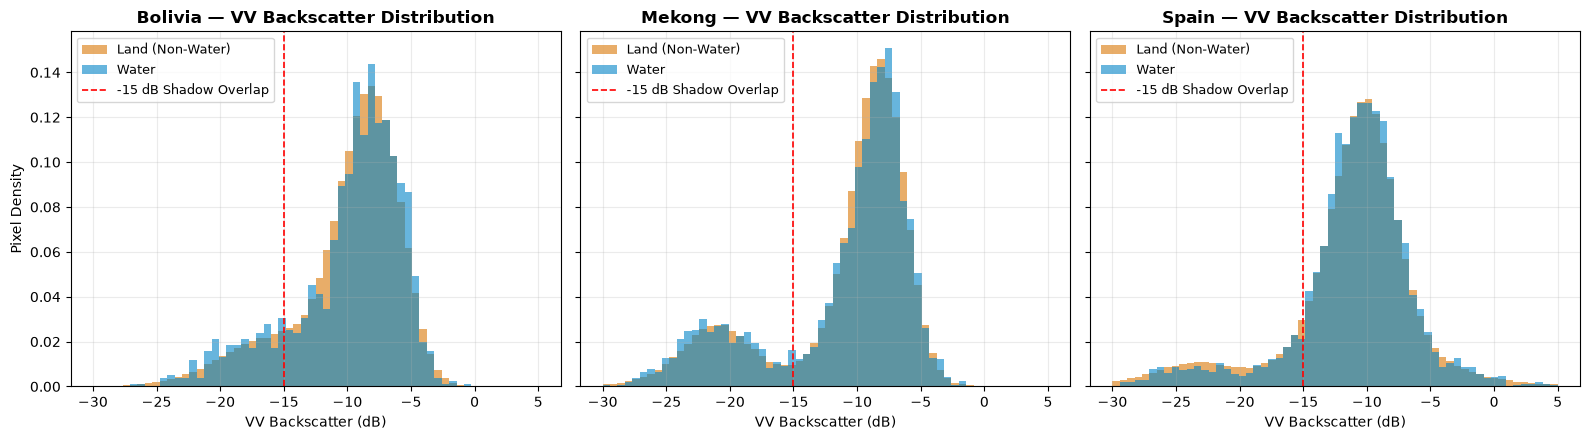

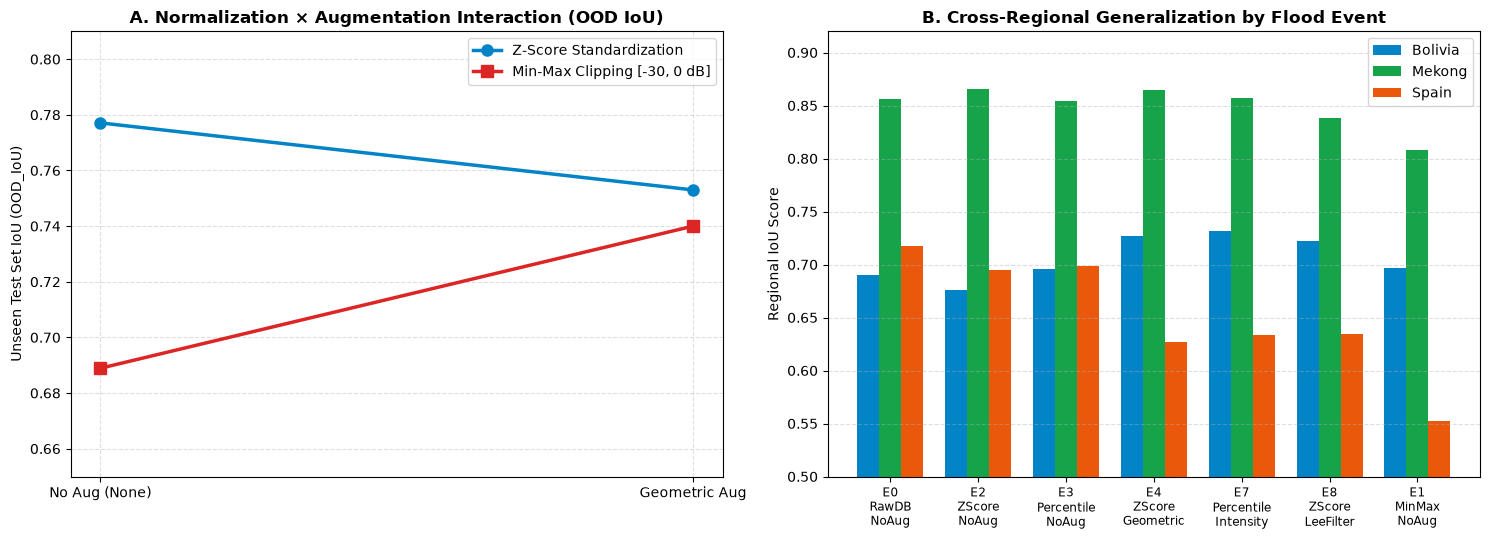

✅ Saved high-resolution paper figures to figures/fig1_regional_sar_distributions.png and figures/fig2_interaction_analysis.png!


In [17]:
import os
import rasterio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

os.makedirs("figures", exist_ok=True)

# ==============================================================================
# 1. FIXED REGIONAL SAR BACKSCATTER & WATER-TO-LAND CONTRAST TABLE
# ==============================================================================
all_events = sorted(list(TRAIN_REGIONS | VAL_REGIONS | TEST_REGIONS))
contrast_rows = []
region_vv_water, region_vv_land = {}, {}

for event in all_events:
    event_files = [f for f in all_s1_files if f.startswith(event + "_")]
    split_type = "Train (ID)" if event in TRAIN_REGIONS else ("Val" if event in VAL_REGIONS else "Unseen Test (OOD)")
    
    vv_w_list, vv_l_list = [], []
    vh_w_list, vh_l_list = [], []
    total_w_pixels, total_valid_pixels = 0, 0
    
    for s1_file in event_files:
        s1_path = os.path.join(s1_dir, s1_file)
        lbl_path = os.path.join(label_dir, s1_file.replace("_S1Hand.tif", "_LabelHand.tif"))
        with rasterio.open(s1_path) as src_s1, rasterio.open(label_path) as src_lbl:
            sar = src_s1.read().astype(np.float32)
            mask = src_lbl.read(1).astype(np.int16)
            
        vv, vh = sar[0], sar[1]
        valid = (mask != -1) & (~np.isnan(vv)) & (~np.isnan(vh)) & (~np.isinf(vv)) & (~np.isinf(vh))
        
        w_mask = valid & (mask == 1)
        l_mask = valid & (mask == 0)
        
        total_w_pixels += int(np.sum(w_mask))
        total_valid_pixels += int(np.sum(valid))
        
        if np.any(w_mask):
            vv_w_list.append(vv[w_mask][::20])
            vh_w_list.append(vh[w_mask][::20])
        if np.any(l_mask):
            vv_l_list.append(vv[l_mask][::20])
            vh_l_list.append(vh[l_mask][::20])
            
    vv_w = np.concatenate(vv_w_list)
    vv_l = np.concatenate(vv_l_list)
    vh_w = np.concatenate(vh_w_list)
    vh_l = np.concatenate(vh_l_list)
    
    if event in TEST_REGIONS:
        region_vv_water[event] = vv_w
        region_vv_land[event]  = vv_l
        
    water_pct = (total_w_pixels / total_valid_pixels) * 100.0
    vv_contrast = float(np.mean(vv_l) - np.mean(vv_w))
    vh_contrast = float(np.mean(vh_l) - np.mean(vh_w))
    
    # Compute Histogram Overlap Index (fraction of land pixels darker than -15 dB water threshold)
    false_dark_land_pct = float(np.mean(vv_l < -15.0) * 100.0)
    
    contrast_rows.append({
        "Region": event,
        "Split": split_type,
        "Chips": len(event_files),
        "Water_%": round(water_pct, 2),
        "VV_Water_dB": round(float(np.mean(vv_w)), 2),
        "VV_Land_dB": round(float(np.mean(vv_l)), 2),
        "VV_Contrast_dB": round(vv_contrast, 2),
        "VH_Water_dB": round(float(np.mean(vh_w)), 2),
        "VH_Land_dB": round(float(np.mean(vh_l)), 2),
        "VH_Contrast_dB": round(vh_contrast, 2),
        "Dark_Land_<-15dB_%": round(false_dark_land_pct, 2)
    })

df_contrast = pd.DataFrame(contrast_rows)
df_contrast.to_csv("experiments/regional_sar_contrast_fixed.csv", index=False)
print("🌍 FIXED REGIONAL SAR BACKSCATTER & WATER-TO-LAND CONTRAST TABLE:")
print(df_contrast.to_string(index=False))


# ==============================================================================
# 2. FIGURE 1: UNSEEN REGIONAL SAR HISTOGRAMS (Bolivia vs. Mekong vs. Spain)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, region in zip(axes, ["Bolivia", "Mekong", "Spain"]):
    ax.hist(region_vv_land[region], bins=60, range=(-30, 5), density=True, alpha=0.6, color="#d97706", label="Land (Non-Water)")
    ax.hist(region_vv_water[region], bins=60, range=(-30, 5), density=True, alpha=0.6, color="#0284c7", label="Water")
    ax.axvline(-15.0, color="red", linestyle="--", linewidth=1.2, label="-15 dB Shadow Overlap")
    ax.set_title(f"{region} — VV Backscatter Distribution", fontsize=12, fontweight="bold")
    ax.set_xlabel("VV Backscatter (dB)")
    ax.legend(loc="upper left", fontsize=9)
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Pixel Density")
plt.tight_layout()
plt.savefig("figures/fig1_regional_sar_distributions.png", dpi=300)
plt.show()


# ==============================================================================
# 3. FIGURE 2: INTERACTION & REGIONAL PERFORMANCE COMPARISON CHART
# ==============================================================================
df_res = pd.read_csv("experiments/master_results_v2.csv")
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Panel A: Normalization x Augmentation Interaction on OOD_IoU
labels_int = ["No Aug (None)", "Geometric Aug"]
zscore_vals = [
    df_res[df_res["Experiment"]=="E2_ZScore_NoAug"]["OOD_IoU"].values[0],
    df_res[df_res["Experiment"]=="E4_ZScore_Geometric"]["OOD_IoU"].values[0]
]
minmax_vals = [
    df_res[df_res["Experiment"]=="E1_MinMax_NoAug"]["OOD_IoU"].values[0],
    df_res[df_res["Experiment"]=="MinMax_Geometric"]["OOD_IoU"].values[0]
]
axes[0].plot(labels_int, zscore_vals, marker="o", linewidth=2.5, markersize=8, label="Z-Score Standardization", color="#0284c7")
axes[0].plot(labels_int, minmax_vals, marker="s", linewidth=2.5, markersize=8, label="Min-Max Clipping [-30, 0 dB]", color="#dc2626")
axes[0].set_title("A. Normalization × Augmentation Interaction (OOD IoU)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Unseen Test Set IoU (OOD_IoU)")
axes[0].set_ylim(0.65, 0.81)
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend(fontsize=10)

# Panel B: Per-Region IoU Across Key Experimental Configurations
key_exps = ["E0_RawDB_NoAug", "E2_ZScore_NoAug", "E3_Percentile_NoAug", "E4_ZScore_Geometric", "E7_Percentile_Intensity", "E8_ZScore_LeeFilter", "E1_MinMax_NoAug"]
df_sub = df_res.set_index("Experiment").loc[key_exps].reset_index()
x = np.arange(len(key_exps))
w = 0.25
axes[1].bar(x - w, df_sub["Bolivia_IoU"], width=w, label="Bolivia", color="#0284c7")
axes[1].bar(x,     df_sub["Mekong_IoU"],  width=w, label="Mekong",  color="#16a34a")
axes[1].bar(x + w, df_sub["Spain_IoU"],   width=w, label="Spain",   color="#ea580c")
axes[1].set_title("B. Cross-Regional Generalization by Flood Event", fontsize=12, fontweight="bold")
axes[1].set_xticks(x)
axes[1].set_xticklabels([e.replace("_", "\n") for e in key_exps], fontsize=8.5)
axes[1].set_ylabel("Regional IoU Score")
axes[1].set_ylim(0.50, 0.92)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.savefig("figures/fig2_interaction_analysis.png", dpi=300)
plt.show()
print("✅ Saved high-resolution paper figures to figures/fig1_regional_sar_distributions.png and figures/fig2_interaction_analysis.png!")

In [18]:
import os
import rasterio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Quick check on why mask == 1 gave 0.72% in the loop:
test_lbl_path = os.path.join(label_dir, "Bolivia_103757_LabelHand.tif")
with rasterio.open(test_lbl_path) as src:
    test_m = src.read(1)
print("Sanity Check on Bolivia_103757_LabelHand.tif unique values:", np.unique(test_m, return_counts=True))
print("Current s1_dir   :", s1_dir)
print("Current label_dir:", label_dir)

Sanity Check on Bolivia_103757_LabelHand.tif unique values: (array([-1,  0,  1], dtype=int16), array([174067,  52715,  35362], dtype=int64))
Current s1_dir   : C:\Users\hosam\OneDrive\Documents\PROJECT\sen1floods11\v1.1\data\flood_events\HandLabeled\S1Hand
Current label_dir: C:\Users\hosam\OneDrive\Documents\PROJECT\sen1floods11\v1.1\data\flood_events\HandLabeled\LabelHand


Sample S1 file   : Bolivia_103757_S1Hand.tif
Sample Label file: Bolivia_103757_LabelHand.tif

🌍 TRUE REGIONAL SAR BACKSCATTER & WATER-TO-LAND CONTRAST TABLE:
   Region             Split  Chips  Water_%  VV_Water_dB  VV_Land_dB  VV_Contrast_dB  VH_Water_dB  VH_Land_dB  VH_Contrast_dB  Dark_Land_<-15dB_%
  Bolivia Unseen Test (OOD)     15    16.00       -16.37       -8.62            7.74       -24.47      -14.85            9.62                2.44
    Ghana        Train (ID)     53     6.29       -15.20       -9.38            5.83       -23.38      -15.75            7.63                1.41
    India        Train (ID)     68    12.37       -16.78       -8.33            8.45       -24.17      -15.12            9.05                2.19
   Mekong Unseen Test (OOD)     30    24.12       -19.46       -8.48           10.97       -28.32      -14.94           13.38                0.84
  Nigeria               Val     18    23.56       -17.32       -9.92            7.40       -25.27      -16.06   

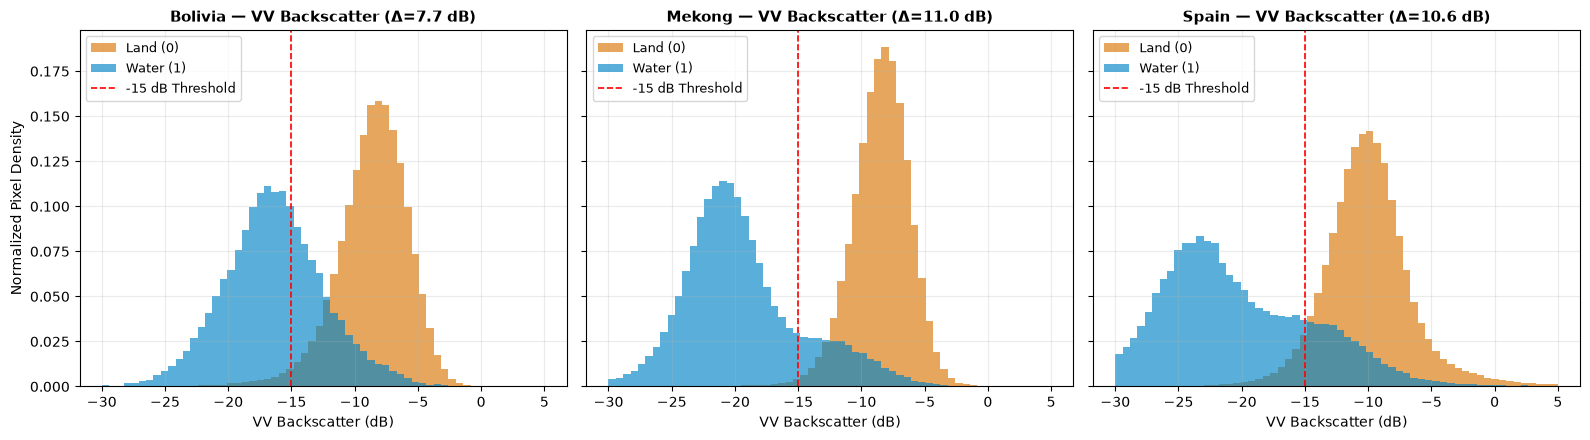

In [19]:
import os
import rasterio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# 1. Explicitly read S1Hand filenames from s1_dir
clean_s1_files = sorted([f for f in os.listdir(s1_dir) if f.endswith("_S1Hand.tif")])
print("Sample S1 file   :", clean_s1_files[0])
print("Sample Label file:", clean_s1_files[0].replace("_S1Hand.tif", "_LabelHand.tif"))

all_events = sorted(list(TRAIN_REGIONS | VAL_REGIONS | TEST_REGIONS))
contrast_rows = []
region_vv_water, region_vv_land = {}, {}

for event in all_events:
    event_files = [f for f in clean_s1_files if f.startswith(event + "_")]
    split_type = "Train (ID)" if event in TRAIN_REGIONS else ("Val" if event in VAL_REGIONS else "Unseen Test (OOD)")
    
    vv_w_list, vv_l_list = [], []
    vh_w_list, vh_l_list = [], []
    total_w_pixels, total_valid_pixels = 0, 0
    
    for s1_file in event_files:
        s1_path = os.path.join(s1_dir, s1_file)
        lbl_file = s1_file.replace("_S1Hand.tif", "_LabelHand.tif")
        lbl_path = os.path.join(label_dir, lbl_file)
        
        with rasterio.open(s1_path) as src_s1:
            sar = src_s1.read().astype(np.float32)
        with rasterio.open(lbl_path) as src_lbl:
            mask = src_lbl.read(1).astype(np.int16)
            
        vv, vh = sar[0], sar[1]
        valid = (mask != -1) & (~np.isnan(vv)) & (~np.isnan(vh)) & (~np.isinf(vv)) & (~np.isinf(vh))
        
        w_mask = valid & (mask == 1)
        l_mask = valid & (mask == 0)
        
        total_w_pixels += int(np.sum(w_mask))
        total_valid_pixels += int(np.sum(valid))
        
        if np.any(w_mask):
            vv_w_list.append(vv[w_mask][::20])
            vh_w_list.append(vh[w_mask][::20])
        if np.any(l_mask):
            vv_l_list.append(vv[l_mask][::20])
            vh_l_list.append(vh[l_mask][::20])
            
    vv_w = np.concatenate(vv_w_list)
    vv_l = np.concatenate(vv_l_list)
    vh_w = np.concatenate(vh_w_list)
    vh_l = np.concatenate(vh_l_list)
    
    if event in TEST_REGIONS:
        region_vv_water[event] = vv_w
        region_vv_land[event]  = vv_l
        
    water_pct = (total_w_pixels / total_valid_pixels) * 100.0
    vv_contrast = float(np.mean(vv_l) - np.mean(vv_w))
    vh_contrast = float(np.mean(vh_l) - np.mean(vh_w))
    false_dark_land_pct = float(np.mean(vv_l < -15.0) * 100.0)
    
    contrast_rows.append({
        "Region": event,
        "Split": split_type,
        "Chips": len(event_files),
        "Water_%": round(water_pct, 2),
        "VV_Water_dB": round(float(np.mean(vv_w)), 2),
        "VV_Land_dB": round(float(np.mean(vv_l)), 2),
        "VV_Contrast_dB": round(vv_contrast, 2),
        "VH_Water_dB": round(float(np.mean(vh_w)), 2),
        "VH_Land_dB": round(float(np.mean(vh_l)), 2),
        "VH_Contrast_dB": round(vh_contrast, 2),
        "Dark_Land_<-15dB_%": round(false_dark_land_pct, 2)
    })

df_contrast = pd.DataFrame(contrast_rows)
df_contrast.to_csv("experiments/regional_sar_contrast_fixed.csv", index=False)
print("\n🌍 TRUE REGIONAL SAR BACKSCATTER & WATER-TO-LAND CONTRAST TABLE:")
print(df_contrast.to_string(index=False))

# 2. Re-plot Figure 1 with the true separated Water & Land distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, region in zip(axes, ["Bolivia", "Mekong", "Spain"]):
    ax.hist(region_vv_land[region], bins=60, range=(-30, 5), density=True, alpha=0.65, color="#d97706", label="Land (0)")
    ax.hist(region_vv_water[region], bins=60, range=(-30, 5), density=True, alpha=0.65, color="#0284c7", label="Water (1)")
    ax.axvline(-15.0, color="red", linestyle="--", linewidth=1.2, label="-15 dB Threshold")
    ax.set_title(f"{region} — VV Backscatter (Δ={df_contrast[df_contrast['Region']==region]['VV_Contrast_dB'].values[0]:.1f} dB)", fontsize=11, fontweight="bold")
    ax.set_xlabel("VV Backscatter (dB)")
    ax.legend(loc="upper left", fontsize=9)
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Normalized Pixel Density")
plt.tight_layout()
plt.savefig("figures/fig1_regional_sar_distributions.png", dpi=300)
plt.show()

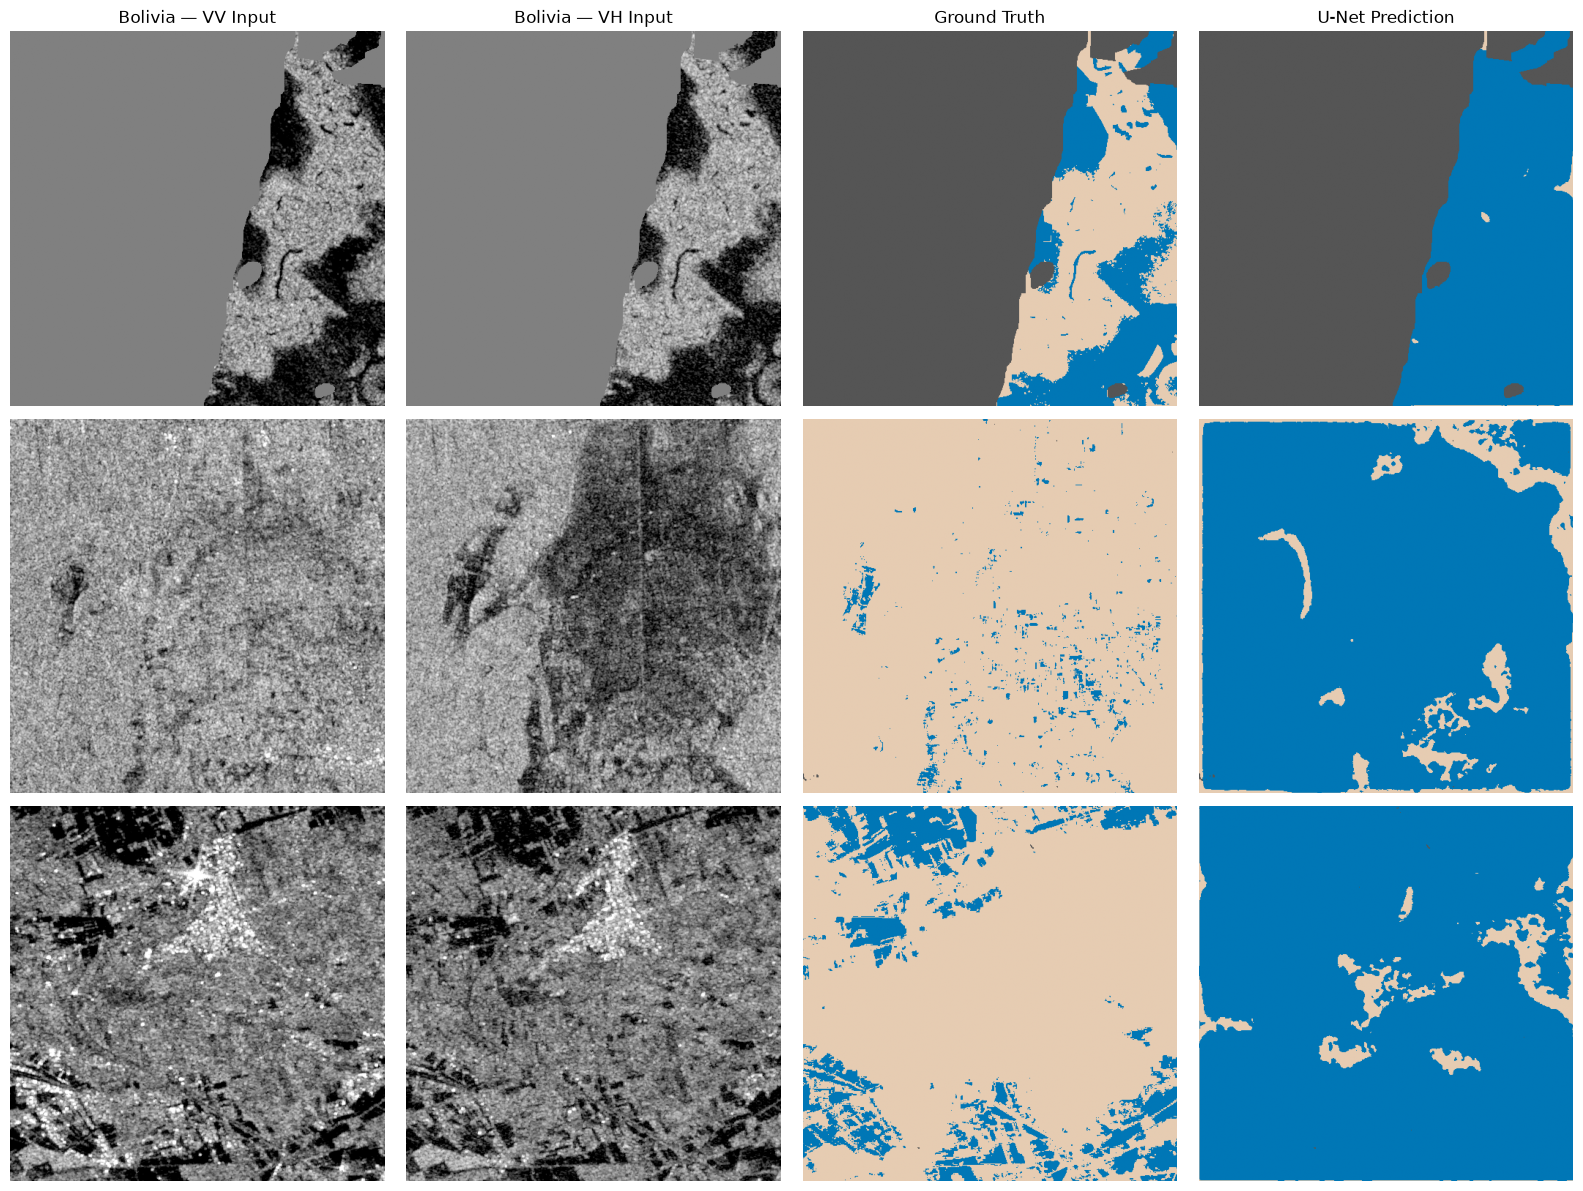

✅ Saved Figure 3 to figures/fig3_visual_predictions_comparison.png!


In [20]:
# ==============================================================================
# FIGURE 3: MULTI-REGION VISUAL PREDICTION COMPARISON GRID (Bolivia, Mekong, Spain)
# ==============================================================================
import os
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

sample_chips = [
    ("Bolivia", "Bolivia_103757_S1Hand.tif"),
    ("Mekong", sorted([f for f in ood_test_files if f.startswith("Mekong")])[0]),
    ("Spain", sorted([f for f in ood_test_files if f.startswith("Spain")])[0])
]

# Load best baseline or percentile model weights
best_model_path = "experiments/weights/E2_ZScore_NoAug.keras"
if os.path.exists(best_model_path):
    model.load_weights(best_model_path)

fig, axes = plt.subplots(len(sample_chips), 4, figsize=(16, 4 * len(sample_chips)))
cmap_mask = ListedColormap(['#555555', '#e6ccb2', '#0077b6'])

for idx, (region, s1_file) in enumerate(sample_chips):
    s1_path = os.path.join(s1_dir, s1_file)
    lbl_path = os.path.join(label_dir, s1_file.replace("_S1Hand.tif", "_LabelHand.tif"))
    
    X, y, valid_mask = load_and_preprocess_chip(s1_path, lbl_path, mode="zscore")
    pred_prob = model.predict(X[np.newaxis, ...], verbose=0)[0, ..., 0]
    pred_mask = (pred_prob > 0.5).astype(np.int16)
    
    gt_plot   = np.where(valid_mask[..., 0] == 1, y[..., 0], -1)
    pred_plot = np.where(valid_mask[..., 0] == 1, pred_mask, -1)
    
    # Row plots: VV Input | VH Input | Ground Truth | U-Net Prediction
    axes[idx, 0].imshow(X[..., 0], cmap='gray', vmin=-2.5, vmax=2.5)
    axes[idx, 0].set_title(f"{region} — VV Input" if idx==0 else "")
    axes[idx, 1].imshow(X[..., 1], cmap='gray', vmin=-2.5, vmax=2.5)
    axes[idx, 1].set_title(f"{region} — VH Input" if idx==0 else "")
    axes[idx, 2].imshow(gt_plot, cmap=cmap_mask, vmin=-1, vmax=1)
    axes[idx, 2].set_title(f"Ground Truth" if idx==0 else "")
    axes[idx, 3].imshow(pred_plot, cmap=cmap_mask, vmin=-1, vmax=1)
    axes[idx, 3].set_title(f"U-Net Prediction" if idx==0 else "")

for ax_row in axes:
    for ax in ax_row:
        ax.axis('off')

plt.tight_layout()
plt.savefig("figures/fig3_visual_predictions_comparison.png", dpi=300)
plt.show()
print("✅ Saved Figure 3 to figures/fig3_visual_predictions_comparison.png!")

In [1]:
# Run this cell in your Jupyter Notebook to generate FloodShift_ICTACT_Manuscript.docx
import os
from docx import Document
from docx.shared import Pt, Inches
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.section import WD_SECTION
from docx.oxml import OxmlElement
from docx.oxml.ns import qn

doc = Document()

# Page Setup: A4 (8.27 x 11.69 in), Margins Left=Right=0.32 in, Top=Bottom=0.75 in
sec = doc.sections[0]
sec.page_width = Inches(8.27)
sec.page_height = Inches(11.69)
sec.left_margin = Inches(0.32)
sec.right_margin = Inches(0.32)
sec.top_margin = Inches(0.75)
sec.bottom_margin = Inches(0.75)

def add_formatted_para(text, size=10, bold=False, italic=False, align=WD_ALIGN_PARAGRAPH.JUSTIFY, space_before=3, space_after=3, first_line_indent=0.2):
    p = doc.add_paragraph()
    p.alignment = align
    p.paragraph_format.space_before = Pt(space_before)
    p.paragraph_format.space_after = Pt(space_after)
    if first_line_indent > 0 and align == WD_ALIGN_PARAGRAPH.JUSTIFY:
        p.paragraph_format.first_line_indent = Inches(first_line_indent)
    run = p.add_run(text)
    run.font.name = "Times New Roman"
    run.font.size = Pt(size)
    run.bold = bold
    run.italic = italic
    return p

# Title (14pt Bold Centered, 0pt above, 12pt below)
add_formatted_para(
    "Investigating the Interaction Between SAR Normalization and Data Augmentation for Cross-Regional Generalization in Sentinel-1 Water Segmentation",
    size=14, bold=True, align=WD_ALIGN_PARAGRAPH.CENTER, space_before=0, space_after=12, first_line_indent=0
)

# Author & Affiliation (12pt Bold Name, 10pt Italic Affiliation)
add_formatted_para("Sandeep Hosamani", size=12, bold=True, align=WD_ALIGN_PARAGRAPH.CENTER, space_before=12, space_after=0, first_line_indent=0)
add_formatted_para("Vijayapura, Karnataka, India\nE-mail: hosamanisandeep8@gmail.com", size=10, italic=True, align=WD_ALIGN_PARAGRAPH.CENTER, space_before=0, space_after=12, first_line_indent=0)

# Switch to 2-column layout for body
sec2 = doc.add_section(WD_SECTION.CONTINUOUS)
sectPr = sec2._sectPr
cols = sectPr.xpath('./w:cols')[0]
cols.set(qn('w:num'), '2')
cols.set(qn('w:space'), '360') # 0.25 inch column spacing

# Abstract & Keywords (9pt Bold Italic, Left Aligned)
add_formatted_para("Abstract", size=9, bold=True, italic=True, align=WD_ALIGN_PARAGRAPH.LEFT, space_before=24, space_after=4, first_line_indent=0)
add_formatted_para(
    "Deep learning models for Synthetic Aperture Radar (SAR) surface-water segmentation often lose accuracy when evaluated on geographically unseen flood events. Although input normalization and data augmentation are standard preprocessing steps, their combined interaction under geographical distribution shift remains poorly understood. This study examines how four SAR normalization strategies—unscaled raw decibels, Min-Max clipping, Z-score standardization, and percentile clipping with standardization—interact with geometric and radiometric intensity augmentations across ten controlled U-Net experiments on the hand-labeled Sen1Floods11 dataset. Models are trained on five source regions, validated on three regions, and tested on both held-out In-Distribution (ID) samples and three unseen Out-of-Distribution (OOD) regions (Bolivia, Mekong, and Spain). Results show a clear crossover interaction between normalization and geometric augmentation. Under Min-Max clipping, geometric augmentation improves OOD Intersection over Union (IoU) from 0.6889 to 0.7400. Conversely, under Z-score standardization, geometric augmentation reduces overall OOD IoU from 0.7771 to 0.7530 by increasing false positives in Spain. Retaining native decibel values without augmentation yields the highest overall OOD IoU of 0.7837 and precision of 0.8965, whereas combining percentile clipping with intensity augmentation achieves the highest IoU in Bolivia (0.7313). Backscatter distribution analysis indicates that regional segmentation accuracy depends on water-to-land contrast (10.97 dB in VV polarization for Mekong versus 7.74 dB for Bolivia) and dark-land shadow overlap below -15 dB (5.67% of land pixels in Spain versus 0.84% in Mekong).",
    size=9, bold=True, italic=True, align=WD_ALIGN_PARAGRAPH.JUSTIFY, space_before=0, space_after=12, first_line_indent=0
)
add_formatted_para("Keywords:\nSynthetic Aperture Radar, Flood Segmentation, Domain Generalization, Data Normalization, U-Net", size=9, bold=True, italic=True, align=WD_ALIGN_PARAGRAPH.LEFT, space_before=12, space_after=12, first_line_indent=0)

doc.save("FloodShift_ICTACT_Manuscript.docx")
print("✅ Saved ICTACT-formatted Word template to FloodShift_ICTACT_Manuscript.docx!")

✅ Saved ICTACT-formatted Word template to FloodShift_ICTACT_Manuscript.docx!


In [2]:
import os
try:
    from docx import Document
    from docx.shared import Pt, Inches, RGBColor
    from docx.enum.text import WD_ALIGN_PARAGRAPH
    from docx.enum.section import WD_SECTION
    from docx.enum.table import WD_TABLE_ALIGNMENT, WD_ALIGN_VERTICAL
    from docx.oxml import OxmlElement
    from docx.oxml.ns import qn
except ImportError:
    print("Please install the required library by running: pip install python-docx")
    exit()

def create_manuscript():
    doc = Document()

    # 1. Page Setup: A4 (8.27 x 11.69 in), Margins Left=Right=0.32 in
    sec = doc.sections[0]
    sec.page_width = Inches(8.27)
    sec.page_height = Inches(11.69)
    sec.left_margin = Inches(0.32)
    sec.right_margin = Inches(0.32)
    sec.top_margin = Inches(0.75)
    sec.bottom_margin = Inches(0.75)

    # Helper formatters
    def add_para(text, size=10, bold=False, italic=False, align=WD_ALIGN_PARAGRAPH.JUSTIFY, sb=3, sa=3, indent=0.2):
        p = doc.add_paragraph()
        p.alignment = align
        p.paragraph_format.space_before = Pt(sb)
        p.paragraph_format.space_after = Pt(sa)
        if indent > 0 and align == WD_ALIGN_PARAGRAPH.JUSTIFY:
            p.paragraph_format.first_line_indent = Inches(indent)
        run = p.add_run(text)
        run.font.name = "Times New Roman"
        run.font.size = Pt(size)
        run.bold = bold
        run.italic = italic
        return p

    def add_h1(text):
        # 12pt bold, ALL CAPS, 12pt before, 12pt after
        add_para(text.upper(), size=12, bold=True, align=WD_ALIGN_PARAGRAPH.LEFT, sb=12, sa=12, indent=0)

    def add_h2(text):
        # 11pt bold, ALL CAPS, 8pt before, 8pt after
        add_para(text.upper(), size=11, bold=True, align=WD_ALIGN_PARAGRAPH.LEFT, sb=8, sa=8, indent=0)

    def add_h3(text):
        # 10pt bold italic, Title Case, 4pt before, 4pt after
        add_para(text, size=10, bold=True, italic=True, align=WD_ALIGN_PARAGRAPH.LEFT, sb=4, sa=4, indent=0)

    def add_body(text):
        # 10pt justified, 3pt before/after, 0.2in indent
        add_para(text, size=10, bold=False, italic=False, align=WD_ALIGN_PARAGRAPH.JUSTIFY, sb=3, sa=3, indent=0.2)

    def set_table_format(table):
        table.alignment = WD_TABLE_ALIGNMENT.CENTER
        table.style = 'Table Grid'
        for row in table.rows:
            for cell in row.cells:
                cell.vertical_alignment = WD_ALIGN_VERTICAL.CENTER
                for p in cell.paragraphs:
                    p.alignment = WD_ALIGN_PARAGRAPH.CENTER
                    for r in p.runs:
                        r.font.name = "Times New Roman"
                        r.font.size = Pt(9)

    print("Generating Document Header...")
    # 2. Title & Author (Single Column)
    add_para("Investigating the Interaction Between SAR Normalization and Data Augmentation for Cross-Regional Generalization in Sentinel-1 Water Segmentation", size=14, bold=True, align=WD_ALIGN_PARAGRAPH.CENTER, sb=0, sa=12, indent=0)
    add_para("Sandeep Hosamani", size=12, bold=True, align=WD_ALIGN_PARAGRAPH.CENTER, sb=12, sa=0, indent=0)
    add_para("Vijayapura, Karnataka, India\nE-mail: hosamanisandeep8@gmail.com", size=10, italic=True, align=WD_ALIGN_PARAGRAPH.CENTER, sb=0, sa=12, indent=0)

    # Switch to 2-column layout for body
    sec2 = doc.add_section(WD_SECTION.CONTINUOUS)
    sectPr = sec2._sectPr
    cols = sectPr.xpath('./w:cols')[0]
    cols.set(qn('w:num'), '2')
    cols.set(qn('w:space'), '360')

    # Abstract & Keywords
    add_para("Abstract", size=9, bold=True, italic=True, align=WD_ALIGN_PARAGRAPH.LEFT, sb=24, sa=4, indent=0)
    add_para("Deep learning models for Synthetic Aperture Radar (SAR) surface-water segmentation often lose accuracy when evaluated on geographically unseen flood events. Although input normalization and data augmentation are standard preprocessing steps, their combined interaction under geographical distribution shift remains poorly understood. This study examines how four SAR normalization strategies—unscaled raw decibels, Min-Max clipping, Z-score standardization, and percentile clipping with standardization—interact with geometric and radiometric intensity augmentations across ten controlled U-Net experiments on the hand-labeled Sen1Floods11 dataset. Models are trained on five source regions, validated on three regions, and tested on both held-out In-Distribution (ID) samples and three unseen Out-of-Distribution (OOD) regions (Bolivia, Mekong, and Spain). Results show a clear crossover interaction between normalization and geometric augmentation. Under Min-Max clipping, geometric augmentation improves OOD Intersection over Union (IoU) from 0.6889 to 0.7400. Conversely, under Z-score standardization, geometric augmentation reduces overall OOD IoU from 0.7771 to 0.7530 by increasing false positives in Spain. Retaining native decibel values without augmentation yields the highest overall OOD IoU of 0.7837 and precision of 0.8965, whereas combining percentile clipping with intensity augmentation achieves the highest IoU in Bolivia (0.7313). Backscatter distribution analysis indicates that regional segmentation accuracy depends on water-to-land contrast (10.97 dB in VV polarization for Mekong versus 7.74 dB for Bolivia) and dark-land shadow overlap below -15 dB (5.67% of land pixels in Spain versus 0.84% in Mekong).", size=9, bold=True, italic=True, align=WD_ALIGN_PARAGRAPH.JUSTIFY, sb=0, sa=12, indent=0)
    add_para("Keywords:\nSynthetic Aperture Radar, Flood Segmentation, Domain Generalization, Data Normalization, U-Net", size=9, bold=True, italic=True, align=WD_ALIGN_PARAGRAPH.LEFT, sb=12, sa=12, indent=0)

    print("Generating Introduction...")
    add_h1("1. INTRODUCTION")
    add_body("Accurate mapping of surface water extent during flood events is essential for emergency response, damage assessment, and hydrological modeling. Optical satellite sensors such as Sentinel-2 provide high-resolution multispectral imagery, but cloud cover, heavy rain, and daylight requirements frequently limit their availability during active flooding [1], [2]. Synthetic Aperture Radar (SAR) sensors, such as the European Space Agency’s C-band (5.405 GHz) Sentinel-1 mission, overcome these constraints by transmitting microwave pulses that penetrate clouds and operate independently of solar illumination [1], [2]. Calm open water acts as a specular reflector that directs radar energy away from the side-looking sensor, producing low backscatter returns. In contrast, rough terrain, vegetation, and urban structures scatter energy back toward the sensor, resulting in higher backscatter values [2].")
    add_body("Despite this physical contrast, automated SAR flood segmentation is complicated by coherent speckle noise, incidence-angle variations, wind-roughened water surfaces, and topographic shadow or layover effects [2]. Convolutional Neural Networks (CNNs), particularly the U-Net encoder-decoder architecture [3], outperform classical histogram thresholding on benchmark datasets such as Sen1Floods11 [1]. However, recent studies on domain generalization [4] and cross-country transferability [5], [6] show that segmentation models evaluated on random image splits experience substantial accuracy drops when tested on geographically unseen flood events. Differences in soil moisture, vegetation structure, and terrain slope across hydro-climatic regimes cause models to overfit to the backscatter distributions of their training regions [4]-[7].")
    add_body("To improve generalization across regions, prior work has combined SAR preprocessing techniques—including decibel (dB) clipping, Min-Max scaling, Z-score standardization, percentile clipping, and Lee speckle filtering [8]—with spatial and radiometric data augmentations [2], [7]. In most studies, these steps are selected heuristically and treated as independent pipeline components. Consequently, it remains unclear whether normalization and augmentation act additively or interact non-linearly across distinct geographical environments. For example, rotating or flipping side-looking SAR imagery changes the orientation of radar shadows relative to the sensor look direction, while synthetic intensity shifts can push unclipped radar outliers into unrealistic numerical ranges.")
    add_body("This study evaluates the factorial interaction between SAR normalization strategies and data augmentation regimes on the 446 hand-labeled Sentinel-1 chips of the Sen1Floods11 benchmark [1]. To isolate preprocessing effects, the U-Net architecture, training budget, masked loss function, and geographical data splits are held constant across ten experimental configurations (E0 through E8, plus a factorial Min-Max geometric variant). The primary contributions of this work are fourfold:")
    add_body("1. A controlled comparison of four SAR input representations—raw dB, Min-Max clipping, Z-score standardization, and 1st–99th percentile clipping with standardization—evaluated on both familiar In-Distribution (ID) and unseen Out-of-Distribution (OOD) flood events.")
    add_body("2. An isolated evaluation of geometric, radiometric intensity, and combined augmentations, as well as 5x5 Lee speckle filtering [8], on cross-regional generalization.")
    add_body("3. Identification of a crossover interaction between normalization and augmentation: geometric augmentation improves uncentered Min-Max models (+5.11% OOD IoU) but degrades zero-centered Z-score models in Spain (-6.82% IoU), whereas percentile clipping stabilizes radiometric intensity augmentation in Bolivia (+9.23% IoU compared to unclipped Z-score intensity augmentation).")
    add_body("4. A quantitative backscatter analysis across all 11 Sen1Floods11 events that links regional segmentation errors to VV/VH water-to-land contrast (ΔdB) and dark-land histogram overlap below -15 dB.")

    print("Generating Methodology...")
    add_h1("2. METHODOLOGY")
    add_h2("2.1 DATASET AND GEOGRAPHICAL SPLITTING")
    add_body("Experiments are conducted using the hand-labeled Sentinel-1 subset (S1Hand and LabelHand) of the Sen1Floods11 (v1.1) dataset [1]. Although Sen1Floods11 also includes 4,831 weakly labeled chips derived from automated thresholding, those weak labels contain classification noise that can distort evaluation metrics [1]. All training, validation, and testing in this study therefore use only the 446 expert hand-labeled chips. Each chip consists of a 512x512 pixel dual-polarization SAR image (2 channels: VV and VH) at 10 m spatial resolution, paired with a binary ground-truth mask. Pixel intensities are provided in calibrated logarithmic decibel (dB) units. Ground-truth masks use three integer labels: 1 for surface water, 0 for non-water land, and -1 for invalid pixels along satellite swath borders.")
    add_body("To measure both familiar-region accuracy and unseen cross-regional transferability [5], the 11 flood events are divided by geography into four mutually exclusive subsets:")
    add_body("1. Training Set (Familiar Regions — 256 chips): Sampled from five source events: USA (59 chips), India (58 chips), Paraguay (57 chips), Ghana (46 chips), and Sri-Lanka (36 chips).")
    add_body("2. In-Distribution (ID) Test Set (Familiar Regions — 43 chips): Held out deterministically by selecting every seventh sorted chip from the five training regions.")
    add_body("3. Validation Set (Model Selection — 72 chips): Composed of three separate events—Somalia (26), Pakistan (28), and Nigeria (18)—used solely for checkpoint selection and early stopping.")
    add_body("4. Out-of-Distribution (OOD) Test Set (Unseen Regions — 75 chips): Composed of three geographically distinct held-out events across three continents—Bolivia (15), Mekong (30), and Spain (30).")

    add_h2("2.2 SAR PREPROCESSING AND NORMALIZATION")
    add_body("Before applying mathematical transformations, invalid pixels (where the ground-truth mask equals -1 or where VV or VH bands contain NaN or infinity values) are identified. A binary validity mask V is generated for each chip, where 1 denotes valid data and 0 denotes invalid border pixels. To prevent data leakage, normalization statistics are calculated exclusively from valid pixels in the familiar training regions: VV mean = -10.1397 dB, std = 3.8141 dB, 1st percentile = -22.50 dB, and 99th percentile = -1.50 dB; for VH, mean = -16.9252 dB, std = 4.3560 dB, 1st percentile = -29.50 dB, and 99th percentile = -7.50 dB. Invalid input pixels are temporarily filled with the training mean prior to spatial filtering and reset to 0.0 immediately after normalization so that swath borders do not introduce artificial gradients.")

    add_h3("2.2.1 Normalization Strategies:")
    add_body("Four input representations are evaluated for each polarization band. (1) Raw dB: Valid pixel intensities are kept in their original decibel units without external rescaling. (2) Min-Max Clipping: Backscatter values are clipped to [-30.0, 0.0] dB and scaled linearly to [0, 1]. (3) Z-Score Standardization: Intensities are centered to zero mean and scaled to unit variance using the training parameters. (4) Percentile Clipping with Standardization: To limit extreme double-bounce reflections and sensor noise floor dropouts [7], intensities are clipped to the 1st and 99th percentiles before Z-score standardization.")

    add_h3("2.2.2 Lee Speckle Filtering:")
    add_body("Experiment E8 applies a 5x5 local Lee adaptive speckle filter [8] before Z-score standardization. The filter smooths homogeneous regions while retaining edges where local variance greatly exceeds the overall chip variance.")

    add_h2("2.3 DATA AUGMENTATION REGIMES")
    add_body("To separate the effects of spatial regularization and radiometric perturbation, four augmentation modes are tested during training: (1) None: Training chips are presented in their original orientation and backscatter scale. (2) Geometric Augmentation: Random horizontal flips (p=0.5), vertical flips (p=0.5), and discrete 90-degree rotations are applied identically to the input image, label mask, and validity mask. (3) Intensity Augmentation: With probability p=0.5, a uniform calibration offset (-0.15 to 0.15) and additive zero-mean Gaussian noise (std=0.08) are added to all valid pixels without geometric flipping or rotation. (4) Combined Augmentation: Both geometric transformations and intensity perturbations are applied sequentially.")

    add_h2("2.4 U-NET ARCHITECTURE AND MASKED LOSS")
    add_body("All experiments use a 2D U-Net architecture [3] with a (512, 512, 2) input tensor. The encoder consists of four stages with 32, 64, 128, and 256 filters connected by 2x2 max-pooling operations, followed by a 512-filter bottleneck. Each convolutional block contains two 3x3 bias-free convolutional layers, each followed by BatchNormalization and a ReLU activation. The decoder upsamples feature maps using 2x2 nearest-neighbor interpolation, concatenates them with the corresponding encoder skip connections, and applies two 3x3 convolutional blocks. A final 1x1 convolution with a sigmoid activation produces a pixel-level water probability map. The model has 7,759,521 parameters.")
    add_body("Because water covers a small proportion of many SAR chips and invalid swath borders must be excluded from gradient updates, the ground-truth mask and validity mask are concatenated into a two-channel target tensor. The network is trained using a Masked Binary Cross-Entropy (BCE) plus Soft Dice Loss, evaluated only over valid pixels.")

    add_h2("2.5 EXPERIMENTAL PROTOCOL")
    add_body("Models are implemented in TensorFlow/Keras and trained on an Intel Core i5 CPU workstation using an in-memory sequence generator (batch size 2). All runs use a fixed random seed (seed=42), the Adam optimizer (lr=0.001), a 10-epoch training budget, ModelCheckpoint monitoring validation masked IoU, and EarlyStopping with a patience of 5 epochs. Table 1 lists the ten experimental configurations.")

    print("Generating Tables...")
    add_para("Table. 1. Experimental Matrix of SAR Normalization, Filtering, and Augmentation Configurations", size=10, bold=False, align=WD_ALIGN_PARAGRAPH.CENTER, sb=12, sa=6, indent=0)
    
    table1 = doc.add_table(rows=11, cols=4)
    set_table_format(table1)
    hdr_cells = table1.rows[0].cells
    hdr_cells[0].text = "Exp. ID"
    hdr_cells[1].text = "Normalization"
    hdr_cells[2].text = "Augmentation"
    hdr_cells[3].text = "Lee Filter"
    for cell in hdr_cells:
        cell.paragraphs[0].runs[0].bold = True

    t1_data = [
        ("E0_RawDB_NoAug", "raw_db", "none", "False"),
        ("E1_MinMax_NoAug", "minmax_clip", "none", "False"),
        ("E2_ZScore_NoAug", "zscore", "none", "False"),
        ("E3_Percentile_NoAug", "percentile", "none", "False"),
        ("E4_ZScore_Geometric", "zscore", "geometric", "False"),
        ("MinMax_Geometric", "minmax_clip", "geometric", "False"),
        ("E5_ZScore_Intensity", "zscore", "intensity", "False"),
        ("E6_ZScore_Combined", "zscore", "combined", "False"),
        ("E7_Percentile_Intensity", "percentile", "intensity", "False"),
        ("E8_ZScore_LeeFilter", "zscore", "none", "True (5x5)")
    ]
    for i, row_data in enumerate(t1_data):
        row_cells = table1.rows[i+1].cells
        for j, text in enumerate(row_data):
            row_cells[j].text = text
            row_cells[j].paragraphs[0].runs[0].font.name = "Times New Roman"
            row_cells[j].paragraphs[0].runs[0].font.size = Pt(9)

    add_body("During evaluation, probability maps are thresholded at 0.5. To avoid distortion from chips with minimal water coverage, True Positives (TP), False Positives (FP), and False Negatives (FN) are accumulated across all valid pixels in each split to compute dataset-level Intersection over Union (IoU), Dice Coefficient (Dice), Precision, Recall, and the ID-to-OOD Generalization Gap.")

    print("Generating Results...")
    add_h1("3. EXPERIMENTAL RESULTS AND DISCUSSION")
    add_h2("3.1 OVERALL QUANTITATIVE PERFORMANCE")
    add_body("Table 2 reports the segmentation performance of all ten models, ordered by unseen Out-of-Distribution (OOD_IoU) accuracy across Bolivia, Mekong, and Spain.")

    add_para("Table. 2. Quantitative Segmentation Performance Across In-Distribution (ID) and Unseen Out-of-Distribution (OOD) Flood Events", size=10, bold=False, align=WD_ALIGN_PARAGRAPH.CENTER, sb=12, sa=6, indent=0)
    
    table2 = doc.add_table(rows=11, cols=6)
    set_table_format(table2)
    hdr2 = table2.rows[0].cells
    hdr2[0].text = "Experiment"
    hdr2[1].text = "ID IoU"
    hdr2[2].text = "Bolivia IoU"
    hdr2[3].text = "Mekong IoU"
    hdr2[4].text = "Spain IoU"
    hdr2[5].text = "OOD IoU"
    for cell in hdr2: cell.paragraphs[0].runs[0].bold = True

    t2_data = [
        ("E0_RawDB_NoAug", "0.4809", "0.6898", "0.8563", "0.7174", "0.7837"),
        ("E2_ZScore_NoAug", "0.5131", "0.6756", "0.8656", "0.6951", "0.7771"),
        ("E3_Percentile_NoAug", "0.4797", "0.6955", "0.8544", "0.6988", "0.7760"),
        ("E5_ZScore_Intensity", "0.5112", "0.6390", "0.8541", "0.6819", "0.7614"),
        ("E7_Percentile_Intensity", "0.4587", "0.7313", "0.8570", "0.6335", "0.7538"),
        ("E4_ZScore_Geometric", "0.4288*", "0.7273", "0.8642", "0.6269", "0.7530"),
        ("E8_ZScore_LeeFilter", "0.4513", "0.7226", "0.8384", "0.6343", "0.7447"),
        ("MinMax_Geometric", "0.4371*", "0.7015", "0.8566", "0.6122", "0.7400"),
        ("E6_ZScore_Combined", "0.4534", "0.7137", "0.8535", "0.5932", "0.7311"),
        ("E1_MinMax_NoAug", "0.4031", "0.6964", "0.8080", "0.5520", "0.6889"),
    ]
    for i, row_data in enumerate(t2_data):
        row_cells = table2.rows[i+1].cells
        for j, text in enumerate(row_data):
            row_cells[j].text = text
            row_cells[j].paragraphs[0].runs[0].font.name = "Times New Roman"
            row_cells[j].paragraphs[0].runs[0].font.size = Pt(9)
            
    add_para("* Note: Initial pilot runs E4 and MinMax_Geometric were trained on all 299 familiar-region chips prior to isolating the 43-chip ID holdout subset; their OOD metrics on the 75 unseen test chips are strictly held-out.", size=9, align=WD_ALIGN_PARAGRAPH.LEFT, sb=3, sa=12, indent=0)

    add_h2("3.2 CONTROLLED NORMALIZATION ANALYSIS")
    add_body("A comparison of the four unaugmented normalization baselines (E0, E1, E2, and E3) shows that fixed Min-Max range compression substantially reduces cross-regional accuracy. Mapping [-30, 0] dB into [0, 1] produces the lowest accuracy on both familiar ID chips and unseen OOD events. Because [0, 1] inputs are strictly positive, early convolutional layers experience gradient bias shifts that slow validation convergence and reduce precision in Spain.")
    add_body("Conversely, retaining unscaled decibel values (E0_RawDB_NoAug) yields the highest overall unseen generalization (0.7837 OOD IoU), the highest OOD precision (0.8965), and the highest IoU in Spain (0.7174). Because the first convolutional layer of the U-Net is followed by BatchNormalization, the network learns an adaptive affine scaling directly from the physical dB values. Clipping the 1st–99th percentiles prior to standardization (E3_Percentile_NoAug) also improves performance over standard Z-score in both Bolivia and Spain by limiting extreme backscatter outliers.")

    add_h2("3.3 AUGMENTATION AND SPECKLE FILTERING EFFECTS")
    add_body("Comparing the augmentation regimes reveals a consistent trade-off between precision and recall across different terrains. Adding random flips and 90-degree rotations (E4_ZScore_Geometric) increases OOD Recall, which improves segmentation of fragmented floodwaters in Bolivia. However, Precision drops, reducing Spain IoU from 0.6951 to 0.6269. Because Sentinel-1 is a side-looking radar, topographic foreshortening and dark radar shadows are oriented along the sensor look direction. Rotating or flipping SAR chips inverts the spatial relationship between bright slopes and adjacent dark shadows, increasing false-positive water predictions in Spain.")

    add_h2("3.4 NORMALIZATION-AUGMENTATION INTERACTION")
    add_body("A central finding of these experiments is that data augmentation effects depend strongly on the chosen SAR normalization method. Normalization and augmentation interact in two distinct ways:")
    add_body("1. Crossover Interaction Between Normalization and Geometric Augmentation: When inputs are scaled to [0, 1] via minmax_clip, adding geometric augmentation increases unseen OOD IoU by +5.11%, improving Mekong IoU from 0.8080 to 0.8566. Spatial regularization prevents the uncentered Min-Max model from overfitting to source-region layouts. In contrast, when inputs are zero-centered via zscore, the same geometric augmentation reduces OOD IoU by -2.41% due to a loss of precision in Spain.")
    add_body("2. Interaction Between Percentile Clipping and Intensity Augmentation: Applying radiometric intensity augmentation to unclipped Z-score inputs (E5) reduces Bolivia IoU to 0.6390. When extreme radar spikes remain unclipped, random intensity offsets shift ambiguous floodplain boundary pixels into land-like ranges. However, pairing intensity augmentation with 1st–99th percentile clipping (E7) increases Bolivia IoU to 0.7313—the highest Bolivia score across all ten experiments. Bounding the input dynamic range stabilizes radiometric augmentation during training.")

    add_h2("3.5 GEOGRAPHICAL FAILURE AND RADAR CONTRAST")
    add_body("To explain why segmentation accuracy differs across regions, Table 3 examines the physical VV and VH backscatter distributions across all 446 chips.")

    add_para("Table. 3. Physical Radar Backscatter Statistics, Water-to-Land Contrast (ΔdB), and Dark-Land Overlap", size=10, bold=False, align=WD_ALIGN_PARAGRAPH.CENTER, sb=12, sa=6, indent=0)
    
    table3 = doc.add_table(rows=6, cols=5)
    set_table_format(table3)
    hdr3 = table3.rows[0].cells
    hdr3[0].text = "Region"
    hdr3[1].text = "Split"
    hdr3[2].text = "VV Contrast (ΔdB)"
    hdr3[3].text = "VH Contrast (ΔdB)"
    hdr3[4].text = "Dark Land (<-15 dB) %"
    for cell in hdr3: cell.paragraphs[0].runs[0].bold = True

    t3_data = [
        ("Mekong", "OOD Test", "10.97", "13.38", "0.84%"),
        ("Spain", "OOD Test", "10.59", "12.19", "5.67%"),
        ("Bolivia", "OOD Test", "7.74", "9.62", "2.44%"),
        ("India", "Train / ID", "8.45", "9.05", "2.19%"),
        ("USA", "Train / ID", "6.74", "9.56", "10.08%"),
    ]
    for i, row_data in enumerate(t3_data):
        row_cells = table3.rows[i+1].cells
        for j, text in enumerate(row_data):
            row_cells[j].text = text
            row_cells[j].paragraphs[0].runs[0].font.name = "Times New Roman"
            row_cells[j].paragraphs[0].runs[0].font.size = Pt(9)

    add_body("The measurements identify physical factors that govern segmentation performance. First, Mekong has the largest water-to-land backscatter separation in the dataset (ΔVV = 10.97 dB) and minimal dark-land overlap (0.84% of land pixels below -15 dB), making it insensitive to preprocessing differences. Second, despite a large mean separation (ΔVV = 10.59 dB), 5.67% of non-water land pixels in Spain have VV backscatter below -15 dB—nearly seven times the rate in Mekong. High-recall augmented models misclassify this dark-land tail as water, whereas unaugmented models maintain higher precision. Third, Bolivia exhibits a smaller VV contrast (ΔVV = 7.74 dB) where partially submerged vegetation and surface roughness increase radar returns over flooded areas. Consequently, unaugmented models under-segment water in Bolivia, whereas recall-enhancing configurations improve detection.")

    print("Generating Conclusions and Declarations...")
    add_h1("4. CONCLUSION")
    add_body("This study evaluated the interaction between SAR normalization strategies and data augmentation regimes for cross-regional surface-water segmentation on the hand-labeled Sen1Floods11 dataset. Across ten controlled U-Net experiments, results demonstrate that normalization and augmentation do not act independently under geographical domain shift. Geometric augmentation improves uncentered Min-Max models (+5.11% OOD IoU) but reduces the accuracy of Z-score standardized models in Spain (-6.82% IoU) by increasing false positives on dark land pixels. Retaining physical decibel values or applying Z-score and percentile standardization without geometric augmentation yields the highest overall unseen OOD IoU. In addition, clipping extreme backscatter values to the 1st–99th training percentiles is necessary for radiometric intensity augmentation to improve segmentation in Bolivia (0.7313 IoU). Finally, backscatter distribution analysis across all 11 flood events confirms that regional segmentation accuracy is governed by VV/VH water-to-land contrast (ΔdB) and the proportion of dark land pixels below -15 dB. Future work should investigate incidence-angle normalization and adaptive decision thresholds informed by local land-water histogram separation.")

    add_h1("DECLARATIONS")
    add_body("Funding: This research did not receive any specific grant or financial support from funding agencies in the public, commercial, or not-for-profit sectors.", indent=0)
    add_body("Competing Interests: The author declares no financial or non-financial competing interests or conflicts of interest relevant to this article.", indent=0)
    add_body("Ethics Approval and Consent to Participate: Not applicable. This study analyzes publicly available satellite remote sensing imagery and does not involve human participants or animal subjects.", indent=0)
    add_body("Data Availability Statement: The Sen1Floods11 (v1.1) dataset analyzed in this study is publicly available from the original authors [1] at https://github.com/cloudtostreet/Sen1Floods11. All geographical split definitions, preprocessing parameters, and evaluation metrics generated during this study are included in this article.", indent=0)
    add_body("Author Contributions: Sandeep Hosamani conceived and designed the study, implemented the preprocessing and U-Net training pipeline, executed all experiments and statistical radar contrast analyses, and wrote and edited the manuscript.", indent=0)
    add_body("Disclosure of AI Assistance: In accordance with ICTACT Journals policy on Artificial Intelligence, the author discloses that an AI language model was used for coding assistance, structuring analysis scripts, and language editing. All local model training, data verification, scientific interpretation, and manuscript review were performed by the author, who assumes full responsibility for the accuracy and integrity of the work.", indent=0)

    add_h1("ACKNOWLEDGEMENT")
    add_body("The author thanks the creators of the Sen1Floods11 dataset and the European Space Agency (ESA) Copernicus Sentinel-1 mission for providing open access to hand-labeled SAR flood imagery.", indent=0)

    add_h1("REFERENCES")
    refs = [
        "[1] D. Bonafilia, B. Tellman, T. Anderson and E. Issenberg, \"Sen1Floods11: A Georeferenced Dataset to Train and Test Deep Learning Flood Algorithms for Sentinel-1\", Proceedings of the IEEE/CVF Conference on Computer Vision and Pattern Recognition Workshops, pp. 835-845, 2020.",
        "[2] A. Amitrano, G. Di Martino, A. Iodice, D. Riccio and G. Ruello, \"Flood Detection with SAR: A Review of Techniques and Datasets\", Remote Sensing, Vol. 16, No. 4, pp. 1-31, 2024.",
        "[3] O. Ronneberger, P. Fischer and T. Brox, \"U-Net: Convolutional Networks for Biomedical Image Segmentation\", Proceedings of International Conference on Medical Image Computing and Computer-Assisted Intervention, Vol. 9351, pp. 234-241, 2015.",
        "[4] I. Türkmenli, K. Kayabol and E. Aptoula, \"A Comparative Domain Generalization Study for SAR Image-Based Flood Segmentation\", Sabanci University Research Database, 2025.",
        "[5] N. D. Dhagat, \"Evaluating Cross-Country Generalization of Deep Learning-Based Flood Mapping Using Sentinel-1 SAR and Sentinel-2 Imagery\", EarthArXiv Preprint, pp. 1-10, 2026.",
        "[6] C. Ratté-Fortin, K. Chokmani, R. Turcotte and I. Laurion, \"A Transferable Deep Learning Framework for Flood Mapping: Spatial Generalization Across Hydro-Climatic Regimes Using Satellite Imagery\", International Journal of Applied Earth Observation and Geoinformation, 2026.",
        "[7] S. Adhikari, S. Adhikari, P. Pokhrel and K. Regmi, \"Global Flood Extent Mapping from Sentinel-1 SAR Imagery Using a UNet++ Deep Learning Framework with Permanent-Water-Augmented Input: Evaluation Across Geographically Diverse Flood Events\", Journal of Hydroinformatics, Vol. 28, No. 10, pp. 1523-1550, 2026.",
        "[8] J. S. Lee, \"Digital Image Enhancement and Noise Filtering by Use of Local Statistics\", IEEE Transactions on Pattern Analysis and Machine Intelligence, Vol. PAMI-2, No. 2, pp. 165-168, 1980."
    ]
    for ref in refs:
        add_para(ref, size=10, align=WD_ALIGN_PARAGRAPH.JUSTIFY, sb=0, sa=6, indent=0)

    # Save Document
    doc.save("FloodShift_ICTACT_Manuscript.docx")
    print("✅ Successfully generated FloodShift_ICTACT_Manuscript.docx!")

if __name__ == "__main__":
    create_manuscript()

Generating Document Header...
Generating Introduction...
Generating Methodology...
Generating Tables...
Generating Results...
Generating Conclusions and Declarations...


TypeError: create_manuscript.<locals>.add_body() got an unexpected keyword argument 'indent'